In [ ]:
import os
import re
import gc
import pickle
import pickle as pk
import datetime as dt
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots

import requests
import shutil
import kagglehub

from datasets.SMD.preprocess_SMD import SMD_Dataset  

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Pickle Save object
def save_obj(obj, filename):
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'wb') as outp:  
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

# Pickle Read Object
def read_obj(filename):
    
    filename = 'CSV data/' + filename + '.pkl'
    with open(filename, 'rb') as inp: 
        return pickle.load(inp)

### Neural ODE

In [ ]:
class TimeEmbedding(nn.Module):

    def __init__(self, embed_dim):
        super().__init__()
        self.embed_dim = embed_dim
        self.linear = nn.Linear(1, embed_dim)
    
    def forward(self, t):

        if t.dim() == 0: 
            t = t.unsqueeze(0)  # (1,)
        if t.dim() == 1:  # (batch_size,) or (1,)
            t = t.unsqueeze(-1)  # (batch_size, 1)
        return self.linear(t)

class ODEFunc(nn.Module):
    def __init__(self, latent_dim, hidden_dim, time_emb_dim):
        super().__init__()
        self.time_embedding = TimeEmbedding(time_emb_dim)
        self.ode_func = nn.Sequential(
            nn.Linear(latent_dim + time_emb_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, latent_dim)
        )
        
    def forward(self, t, z):
        original_shape = z.shape
        if t.dim() == 0:
            t = t.unsqueeze(0)
        
        if z.dim() == 3:
            seq_len, batch_size, latent_dim = z.shape
            z_flat = z.view(-1, latent_dim)
            t_expanded = t.expand(seq_len * batch_size)
            t_emb = self.time_embedding(t_expanded)
        elif z.dim() == 2:
            batch_size, latent_dim = z.shape
            z_flat = z
            t_expanded = t.expand(batch_size)
            t_emb = self.time_embedding(t_expanded)
        else:
            raise ValueError(f"Unexpected z dimension: {z.shape}")
        
        z_with_time = torch.cat([z_flat, t_emb], dim=-1)
        dz_dt = self.ode_func(z_with_time)
        
        return dz_dt.view(original_shape)

class AugmentedODEFunc(nn.Module):
    def __init__(self, ode_func, noise_enabled=False, noise_decay=2.0, noise_coupling=0.1):
        super().__init__()
        self.ode_func = ode_func
        self.noise_enabled = noise_enabled
        self.noise_decay = noise_decay
        self.noise_coupling = noise_coupling
        
    def forward(self, t, state):
        if self.noise_enabled:
            z, d, n = state
        else:
            z, d = state
        dz_dt = self.ode_func(t, z)
        dd_dt = torch.mean(dz_dt.pow(2), dim=-1)
        
        if self.noise_enabled:
            dn_dt = -self.noise_decay * n + self.noise_coupling * dz_dt
            return (dz_dt, dd_dt, dn_dt)
        
        return (dz_dt, dd_dt)

class ODERNNEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim, time_emb_dim):
        super().__init__()
        self.time_embedding = TimeEmbedding(time_emb_dim)
        self.rnn = nn.GRU(input_dim + time_emb_dim, hidden_dim, batch_first=True)
        self.to_mu = nn.Linear(hidden_dim, latent_dim)
        self.to_logvar = nn.Linear(hidden_dim, latent_dim)
        
    def forward(self, x, times, mask=None):
        batch_size = x.size(0)
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(batch_size, -1)
        
        t_emb = self.time_embedding(times.unsqueeze(-1))
        x_with_time = torch.cat([x, t_emb], dim=-1)
        rnn_out, _ = self.rnn(x_with_time)
        
        final_hidden = rnn_out[:, -1, :]
        mu = self.to_mu(final_hidden)
        logvar = self.to_logvar(final_hidden)
        
        std = torch.exp(0.5 * logvar)
        z0 = mu + torch.randn_like(std) * std
        
        return z0, mu, logvar

class ProbabilisticDecoder(nn.Module):
    def __init__(self, latent_dim, input_dim, hidden_dim):
        super().__init__()
        self.input_dim = input_dim
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim * 2)
        )
        
    def forward(self, z_trajectory):
        original_shape = z_trajectory.shape
        if z_trajectory.dim() == 3:
            z_flat = z_trajectory.reshape(-1, z_trajectory.shape[-1])
        elif z_trajectory.dim() == 2:
            z_flat = z_trajectory
        else:
            raise ValueError(f"Unexpected z_trajectory dimension: {z_trajectory.shape}")
        
        decoded = self.decoder(z_flat)
        mu_flat = decoded[..., :self.input_dim]
        logvar_flat = decoded[..., self.input_dim:]
        
        if z_trajectory.dim() == 3:
            seq_len, batch_size = original_shape[:2]
            mu = mu_flat.reshape(seq_len, batch_size, self.input_dim)
            logvar = logvar_flat.reshape(seq_len, batch_size, self.input_dim)
        else:
            batch_size = original_shape[0]
            mu = mu_flat.reshape(batch_size, self.input_dim)
            logvar = logvar_flat.reshape(batch_size, self.input_dim)
        
        return mu, logvar

In [37]:
def init_model_weights(model):
    for name, param in model.named_parameters():
        if 'weight' in name and param.dim() >= 2:
            nn.init.xavier_uniform_(param)
        elif 'bias' in name:
            nn.init.zeros_(param)

In [54]:
class RobustGradientSpikeDetector(nn.Module):
    def __init__(
        self,
        input_dim,
        latent_dim=32,
        hidden_dim=64,
        time_emb_dim=8,
        beta=0.1,
        noise_enabled=False,
        noise_decay=2.0,
        noise_coupling=0.1,
        noise_loss_weight=0.05,
    ):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.beta = beta
        self.noise_enabled = noise_enabled
        self.noise_loss_weight = noise_loss_weight
        
        self.encoder = ODERNNEncoder(input_dim, hidden_dim, latent_dim, time_emb_dim)
        self.ode_func = ODEFunc(latent_dim, hidden_dim, time_emb_dim)
        self.augmented_ode_func = AugmentedODEFunc(
            self.ode_func,
            noise_enabled=noise_enabled,
            noise_decay=noise_decay,
            noise_coupling=noise_coupling,
        )
        self.decoder = ProbabilisticDecoder(latent_dim, input_dim, hidden_dim)
        self.gradient_scale = nn.Parameter(torch.tensor(1.0))
        if self.noise_enabled:
            self.noise_projector = nn.Sequential(
                nn.Linear(latent_dim, latent_dim),
                nn.Tanh(),
            )
        else:
            self.noise_projector = None
    
    def compute_gradients(self, z_trajectory, times, return_deltas=False):
        if len(z_trajectory) <= 1:
            zero_tensor = torch.zeros_like(z_trajectory)
            if return_deltas:
                return zero_tensor, torch.tensor([], device=z_trajectory.device)
            return zero_tensor
        if times.dim() > 1:
            base_times = times[0] if times.dim() > 1 else times
        else:
            base_times = times
        delta_t = torch.diff(base_times.to(z_trajectory.device))
        delta_t = torch.clamp(delta_t, min=1e-6)
        reshape_dims = (-1,) + (1,) * (z_trajectory.dim() - 1)
        dz_dt = torch.diff(z_trajectory, dim=0) / delta_t.view(reshape_dims)
        last_grad = dz_dt[-1:] if len(dz_dt) > 0 else torch.zeros(1, *z_trajectory.shape[1:], device=z_trajectory.device)
        grads = torch.cat([dz_dt, last_grad], dim=0) * self.gradient_scale
        if return_deltas:
            return grads, delta_t
        return grads
    
    def compute_spike_indicators(self, gradients):
        if len(gradients) <= 1:
            batch_size = gradients.shape[1] if gradients.dim() > 1 else 1
            device = gradients.device
            return torch.zeros(batch_size, device=device), torch.zeros(batch_size, device=device)
        
        grad_norms = torch.norm(gradients, dim=-1)
        sudden_spikes = torch.max(torch.abs(torch.diff(grad_norms, dim=0)), dim=0)[0] if len(grad_norms) > 1 else torch.zeros(grad_norms.shape[1], device=gradients.device)
        gradual_spikes = torch.mean(grad_norms, dim=0)
        return sudden_spikes, gradual_spikes
    
    def _compute_irregularity_metric(self, gradients, delta_t):
        if len(gradients) <= 1 or delta_t.numel() == 0:
            return None
        effective_grads = gradients[:-1]
        if effective_grads.dim() >= 3:
            magnitudes = torch.norm(effective_grads, dim=-1)
        else:
            magnitudes = torch.abs(effective_grads)
        weights = delta_t.view(-1, *([1] * (magnitudes.dim() - 1)))
        weighted = magnitudes * weights
        return torch.mean(weighted, dim=0)
    
    def _ode_integrate(self, augmented_z0, unique_times):
        try:
            return odeint(
                self.augmented_ode_func,
                augmented_z0,
                unique_times,
                method='dopri5',
                rtol=1e-4,
                atol=1e-6,
                options={'max_num_steps': 1000},
            )
        except Exception:
            try:
                return odeint(self.augmented_ode_func, augmented_z0, unique_times, method='euler')
            except Exception:
                seq_len = len(unique_times)
                if self.noise_enabled:
                    z0, d0, n0 = augmented_z0
                else:
                    z0, d0 = augmented_z0
                    n0 = None
                z_rep = z0.unsqueeze(0).expand(seq_len, -1, -1)
                d_rep = d0.unsqueeze(0).expand(seq_len, -1)
                if self.noise_enabled:
                    n_rep = n0.unsqueeze(0).expand(seq_len, -1, -1)
                    return (z_rep, d_rep, n_rep)
                return (z_rep, d_rep)
    
    def forward(self, x, times, mask=None):
        if times.dim() == 1:
            times = times.unsqueeze(0).expand(x.size(0), -1)
        
        z_latent, mu, logvar = self.encoder(x, times, mask)
        batch_size = z_latent.size(0)
        seq_len = x.size(1)
        unique_times = torch.linspace(0, 1, seq_len).to(x.device)
        
        if self.noise_enabled:
            z_noise = self.noise_projector(z_latent)
            z0 = z_latent - z_noise
            noise_init = z_noise
        else:
            z0 = z_latent
            noise_init = None
        
        augmented_z0 = (z0, torch.zeros(batch_size, device=z0.device))
        if self.noise_enabled:
            augmented_z0 = (z0, torch.zeros(batch_size, device=z0.device), noise_init)
        integration_result = self._ode_integrate(augmented_z0, unique_times)
        if self.noise_enabled:
            z_trajectory, d_trajectory, n_trajectory = integration_result
        else:
            z_trajectory, d_trajectory = integration_result
            n_trajectory = None
        
        gradients = self.compute_gradients(z_trajectory, unique_times)
        sudden_spikes, gradual_spikes = self.compute_spike_indicators(gradients)
        mu_recon, logvar_recon = self.decoder(z_trajectory)
        
        losses = self.compute_loss(
            x,
            mu_recon,
            mu,
            logvar,
            gradients,
            d_trajectory[-1],
            noise_traj=n_trajectory,
        )
        
        return {
            'mu_recon': mu_recon,
            'logvar_recon': logvar_recon,
            'z_trajectory': z_trajectory,
            'noise_trajectory': n_trajectory,
            'gradients': gradients,
            'sudden_spikes': sudden_spikes,
            'gradual_spikes': gradual_spikes,
            'mu': mu,
            'logvar': logvar,
            'losses': losses,
            'final_drift': d_trajectory[-1],
            'initial_noise': noise_init,
        }
    
    def compute_loss(self, x, mu_recon, mu, logvar, gradients, final_drift, noise_traj=None):
        x_expanded = x.transpose(0, 1)
        min_len = min(mu_recon.size(0), x_expanded.size(0))
        recon_delta = mu_recon[:min_len] - x_expanded[:min_len]
        recon_loss = F.mse_loss(recon_delta, torch.zeros_like(recon_delta), reduction='mean')
        recon_step_error = torch.mean(recon_delta ** 2, dim=-1)
        
        logvar_clamped = torch.clamp(logvar, min=-10, max=10)
        kl_loss = -0.5 * torch.sum(1 + logvar_clamped - mu.pow(2) - logvar_clamped.exp()) / x.size(0)
        
        grad_smoothness = torch.mean(torch.diff(gradients, dim=0) ** 2) if len(gradients) > 1 else torch.tensor(0.0, device=x.device)
        drift_loss = torch.mean(final_drift)
        alignment_loss = torch.tensor(0.0, device=x.device)
        if noise_traj is not None:
            noise_energy = torch.norm(noise_traj[:min_len], dim=-1)
            noise_norm = (noise_energy - noise_energy.mean()) / (noise_energy.std() + 1e-6)
            recon_norm = (recon_step_error - recon_step_error.mean()) / (recon_step_error.std() + 1e-6)
            alignment_loss = F.mse_loss(noise_norm, recon_norm)
        
        total_loss = (
            recon_loss
            + self.beta * kl_loss
            + 0.01 * grad_smoothness
            + 0.1 * drift_loss
            + self.noise_loss_weight * alignment_loss
        )
        
        return {
            'total_loss': torch.clamp(total_loss, min=1e-8),
            'recon_loss': recon_loss,
            'kl_loss': kl_loss,
            'grad_smoothness': grad_smoothness,
            'drift_loss': drift_loss,
            'noise_alignment': alignment_loss,
        }
    
    def _compute_score(
        self,
        x,
        z_trajectory,
        d_trajectory,
        times,
        mu,
        logvar,
        is_forward=True,
        noise_trajectory=None,
        return_components=False,
    ):
        gradients, delta_t = self.compute_gradients(z_trajectory, times, return_deltas=True)
        sudden_spikes, gradual_spikes = self.compute_spike_indicators(gradients)
        mu_recon, _ = self.decoder(z_trajectory)
        
        x_expanded = x.transpose(0, 1)
        min_len = min(mu_recon.size(0), x_expanded.size(0))
        recon_time = torch.mean((mu_recon[:min_len] - x_expanded[:min_len]) ** 2, dim=-1)
        recon_errors = torch.mean(recon_time, dim=0)
        noise_energy = None
        noise_time = None

        if noise_trajectory is not None:
            noise_time = torch.norm(noise_trajectory[:min_len], dim=-1)
            noise_energy = torch.mean(noise_time, dim=0)
        
        grad_anomaly = None
        grad_energy = None
        irregularity = self._compute_irregularity_metric(gradients, delta_t)
        kl_divs = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=-1)

        if len(gradients) > 0:
            grad_energy = torch.norm(gradients, dim=-1)
            grad_anomaly = torch.mean(grad_energy, dim=0)
            weights = (0.5, 0.15, 0.15, 0.1, 0.05, 0.05) if is_forward else (0.4, 0.2, 0.1, 0.15, 0.1, 0.05)
            score = (
                weights[0] * recon_errors
                + weights[1] * d_trajectory[-1]
                + weights[2] * grad_anomaly
                + weights[3] * sudden_spikes
                + weights[4] * gradual_spikes
                + weights[5] * kl_divs
            )

            if noise_energy is not None:
                noise_weight = 0.1 if is_forward else 0.12
                score = score + noise_weight * noise_energy
        else:
            score = 0.7 * recon_errors + 0.3 * d_trajectory[-1]
            if noise_energy is not None:
                score = score + 0.1 * noise_energy
        
        if return_components:
            components = {
                'recon_errors': recon_errors,
                'recon_time': recon_time,
                'noise_energy': noise_energy,
                'noise_time': noise_time,
                'grad_anomaly': grad_anomaly,
                'grad_energy': grad_energy,
                'sudden_spikes': sudden_spikes,
                'gradual_spikes': gradual_spikes,
                'kl_divs': kl_divs,
                'drift': d_trajectory[-1],
                'irregularity': irregularity,
            }
            return score, components
        return score
    
    def anomaly_score(self, x, times, mask=None, direction='both'):
        self.eval()
        with torch.no_grad():
            if times.dim() == 1:
                times = times.unsqueeze(0).expand(x.size(0), -1)
            
            z_latent, mu, logvar = self.encoder(x, times, mask)
            seq_len = x.size(1)
            unique_times = torch.linspace(0, 1, seq_len).to(x.device)
            
            if self.noise_enabled:
                z_noise = self.noise_projector(z_latent)
                z0 = z_latent - z_noise
                noise_init = z_noise
            else:
                z0 = z_latent
                noise_init = None
            
            def build_initial_state():
                drift0 = torch.zeros(z0.size(0), device=z0.device)
                if self.noise_enabled:
                    return (z0, drift0, noise_init)
                return (z0, drift0)
            
            if direction in ['forward', 'both']:
                forward_state = build_initial_state()
                integration_result = self._ode_integrate(forward_state, unique_times)
                if self.noise_enabled:
                    z_fw, d_fw, n_fw = integration_result
                else:
                    z_fw, d_fw = integration_result
                    n_fw = None
                forward_scores = self._compute_score(
                    x,
                    z_fw,
                    d_fw,
                    unique_times,
                    mu,
                    logvar,
                    True,
                    noise_trajectory=n_fw,
                )
            
            if direction in ['backward', 'both']:
                reverse_times = torch.flip(unique_times, dims=[0])
                backward_state = build_initial_state()
                integration_result = self._ode_integrate(backward_state, reverse_times)
                if self.noise_enabled:
                    z_bw, d_bw, n_bw = integration_result
                else:
                    z_bw, d_bw = integration_result
                    n_bw = None
                backward_scores = self._compute_score(
                    x,
                    z_bw,
                    d_bw,
                    reverse_times,
                    mu,
                    logvar,
                    False,
                    noise_trajectory=n_bw,
                )
            
            if direction == 'forward':
                return forward_scores.cpu().numpy()
            elif direction == 'backward':
                return backward_scores.cpu().numpy()
            else:
                return (0.6 * forward_scores + 0.4 * backward_scores).cpu().numpy()


### Integrated Code

In [55]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from torch.utils.data import DataLoader, TensorDataset

def unified_load_and_prepare_data(dataset_path, batch_size=64, window_size=50, stride=1, 
                                   normalize=True, device=None):

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    print(f"Loading dataset: {dataset_path}")
    with open(dataset_path, 'rb') as f:
        data = pk.load(f)
    
    if 'x_trn' in data and 'x_tst' in data and 'lab_tst' in data:
        x_trn = data['x_trn']
        x_tst = data['x_tst']
        lab_tst = data['lab_tst']
        
        # prioritize trimSyn detection using the file path hint
        dataset_path_lower = dataset_path.lower()
        is_trimSyn_path = 'trimsyn' in dataset_path_lower
        
        # infer overall data layout
        if isinstance(x_trn, list) and len(x_trn) > 0:
            if is_trimSyn_path:
                # explicit trimSyn path hint
                data_type = 'trimSyn'
            elif len(x_trn[0].shape) == 3:  # (samples, time, features) - trimSyn
                data_type = 'trimSyn'
            elif len(x_trn[0].shape) == 2: 
                if is_trimSyn_path or len(x_trn) != 28:
                    data_type = 'trimSyn'
                else:
                    data_type = 'SMD'
                    entity_idx = 0
                    x_trn = x_trn[entity_idx]
                    x_tst = x_tst[entity_idx]
                    lab_tst = lab_tst[entity_idx] if isinstance(lab_tst, list) else lab_tst
            else:
                data_type = 'Unknown'
        elif isinstance(x_trn, np.ndarray):
            data_type = 'Single'  # e.g., SWaT or WADI style datasets
        else:
            data_type = 'Unknown'
    else:
        return None, 'Unknown', None
    
    print(f"Detected data type: {data_type}")
    
    # Data preprocessing
    if data_type == 'trimSyn':
        # trimSyn keeps the original list structure
        x_trn_all = x_trn
        x_tst_all = x_tst
        lab_tst_all = lab_tst
        
        # determine input dimension from the first sample
        input_dim = x_trn_all[0].shape[-1]
        
        # normalization
        if normalize:
            # fit scaler on all samples combined
            x_trn_flat = np.concatenate([x.reshape(-1, input_dim) for x in x_trn_all], axis=0)
            scaler = MinMaxScaler(feature_range=(-1, 1))
            scaler.fit(x_trn_flat)
            
            x_trn_all = [scaler.transform(x.reshape(-1, input_dim)).reshape(x.shape) 
                         for x in x_trn_all]
            x_tst_all = [scaler.transform(x.reshape(-1, input_dim)).reshape(x.shape) 
                         for x in x_tst_all]
        
        # ensure (samples, seq_len, features) per section
        def _ensure_3d(array):
            if array.ndim == 3:
                return array
            if array.ndim == 2:
                return array[np.newaxis, ...]
            if array.ndim == 1:
                return array[np.newaxis, :, np.newaxis]
            raise ValueError(f"Unsupported trimSyn array shape: {array.shape}")
        
        x_trn_all = [_ensure_3d(x) for x in x_trn_all]
        x_tst_all = [_ensure_3d(x) for x in x_tst_all]
        input_dim = x_trn_all[0].shape[-1]
        
        # convert to tensors
        x_trn_tensors = [torch.FloatTensor(x) for x in x_trn_all]
        x_tst_tensors = [torch.FloatTensor(x) for x in x_tst_all]
        # keep label lists as-is because sections may differ in length
        lab_tst_list = lab_tst_all
        
        # build per-section DataLoaders with matching time grids
        train_loaders = []
        for x_tensor in x_trn_tensors:
            seq_len = x_tensor.shape[1]
            time_steps = torch.linspace(0, 1, seq_len, dtype=x_tensor.dtype)
            time_steps = time_steps.unsqueeze(0).repeat(x_tensor.shape[0], 1)
            train_dataset = TensorDataset(x_tensor, time_steps)
            train_loaders.append(DataLoader(train_dataset, batch_size=batch_size, shuffle=False))
        
        data_dict = {
            'train_loaders': train_loaders,
            'x_tst': x_tst_tensors,
            'lab_tst': lab_tst_list,  # 리스트 형태로 저장
            'data_type': 'trimSyn',
            'scaler': scaler if normalize else None
        }
        
    elif data_type == 'SMD':
        # SMD uses 2D arrays
        input_dim = x_trn.shape[-1]
        
        # normalization
        if normalize:
            scaler = StandardScaler()
            x_trn = scaler.fit_transform(x_trn)
            x_tst = scaler.transform(x_tst)
        
        # sliding window helper
        def create_windows(data, window_size, stride):
            windows = []
            for i in range(0, len(data) - window_size + 1, stride):
                windows.append(data[i:i+window_size])
            return np.array(windows)
        
        x_trn_windows = create_windows(x_trn, window_size, stride)
        x_tst_windows = create_windows(x_tst, window_size, stride)
        
        # label handling
        if lab_tst.ndim == 2:
            lab_tst_windows = np.max(lab_tst[window_size-1:], axis=1)
        else:
            lab_tst_windows = lab_tst[window_size-1:]
        
        # convert to tensors
        seq_len = window_size
        time_steps = torch.linspace(0, 1, seq_len)
        
        train_dataset = TensorDataset(
            torch.FloatTensor(x_trn_windows),
            time_steps.repeat(len(x_trn_windows), 1)
        )
        test_dataset = TensorDataset(
            torch.FloatTensor(x_tst_windows),
            time_steps.repeat(len(x_tst_windows), 1),
            torch.FloatTensor(lab_tst_windows)
        )
        
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
        
        data_dict = {
            'train_loader': train_loader,
            'test_loader': test_loader,
            'x_tst': torch.FloatTensor(x_tst_windows),
            'lab_tst': torch.FloatTensor(lab_tst_windows),
            'data_type': 'SMD',
            'scaler': scaler if normalize else None
        }
        
    elif data_type == 'Single':
        # Single-stream datasets such as SWaT or WADI
        input_dim = x_trn.shape[-1]
        
        # normalization
        if normalize:
            scaler = StandardScaler()
            x_trn = scaler.fit_transform(x_trn)
            x_tst = scaler.transform(x_tst)
        
        # sliding window helper
        def create_windows(data, window_size, stride):
            windows = []
            for i in range(0, len(data) - window_size + 1, stride):
                windows.append(data[i:i+window_size])
            return np.array(windows)
        
        x_trn_windows = create_windows(x_trn, window_size, stride)
        x_tst_windows = create_windows(x_tst, window_size, stride)
        
        # label handling
        if lab_tst.ndim == 1:
            lab_tst_windows = lab_tst[window_size-1::stride]
        else:
            lab_tst_windows = np.max(lab_tst[window_size-1:], axis=1)
        
        # convert to tensors
        seq_len = window_size
        time_steps = torch.linspace(0, 1, seq_len)
        
        train_dataset = TensorDataset(
            torch.FloatTensor(x_trn_windows),
            time_steps.repeat(len(x_trn_windows), 1)
        )
        test_dataset = TensorDataset(
            torch.FloatTensor(x_tst_windows),
            time_steps.repeat(len(x_tst_windows), 1),
            torch.FloatTensor(lab_tst_windows)
        )
        
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
        
        data_dict = {
            'train_loader': train_loader,
            'test_loader': test_loader,
            'x_tst': torch.FloatTensor(x_tst_windows),
            'lab_tst': torch.FloatTensor(lab_tst_windows),
            'data_type': 'Single',
            'scaler': scaler if normalize else None
        }
    else:
        return None, 'Unknown', None
    
    print(f"데이터 전처리 완료!")
    print(f"  입력 차원: {input_dim}")
    if data_type == 'trimSyn':
        print(f"  훈련 샘플 수: {len(x_trn_all)}")
        print(f"  테스트 샘플 수: {len(x_tst_all)}")
    else:
        print(f"  훈련 윈도우 수: {len(data_dict['train_loader'].dataset)}")
        print(f"  테스트 윈도우 수: {len(data_dict['test_loader'].dataset)}")
    
    return data_dict, data_type, input_dim


DEFAULT_TOPK_RATIO = 0.01


def _compute_metrics(scores, labels, name="Global"):
    import numpy as np
    from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

    scores = np.asarray(scores)
    labels = np.asarray(labels)
    if len(scores) == 0 or len(labels) == 0:
        return {
            'name': name,
            'threshold': None,
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0,
            'auc': 0.5,
            'accuracy': 0.0,
            'positive_ratio': 0.0,
            'count': 0,
            'fallback_used': False,
        }

    min_len = min(len(scores), len(labels))
    scores = scores[:min_len]
    labels = labels[:min_len]

    thresholds = np.percentile(scores, np.linspace(80, 99.5, min(50, len(scores))))
    if np.all(scores == scores[0]):
        thresholds = np.array([scores[0]])

    best = {
        'f1': -1,
        'threshold': thresholds[0],
        'precision': 0.0,
        'recall': 0.0,
        'accuracy': 0.0,
        'fallback_used': False,
    }

    for threshold in thresholds:
        predictions = (scores > threshold).astype(int)
        f1_val = f1_score(labels, predictions, zero_division=0)
        if f1_val > best['f1']:
            best.update({
                'f1': f1_val,
                'threshold': threshold,
                'precision': precision_score(labels, predictions, zero_division=0),
                'recall': recall_score(labels, predictions, zero_division=0),
                'accuracy': accuracy_score(labels, predictions),
                'fallback_used': False,
            })

    pos_count = int(labels.sum())
    if pos_count > 0 and best['f1'] <= 0:
        top_k = max(1, pos_count)
        top_k = min(len(scores), top_k)
        sorted_scores = np.sort(scores)[::-1]
        threshold = sorted_scores[top_k - 1] - 1e-8
        predictions = (scores >= threshold).astype(int)
        best.update({
            'f1': f1_score(labels, predictions, zero_division=0),
            'threshold': threshold,
            'precision': precision_score(labels, predictions, zero_division=0),
            'recall': recall_score(labels, predictions, zero_division=0),
            'accuracy': accuracy_score(labels, predictions),
            'fallback_used': True,
        })

    try:
        auc = roc_auc_score(labels, scores)
    except Exception:
        auc = 0.5

    return {
        'name': name,
        'threshold': best['threshold'],
        'precision': best['precision'],
        'recall': best['recall'],
        'f1': best['f1'],
        'auc': auc,
        'accuracy': best['accuracy'],
        'positive_ratio': float(np.mean(labels)),
        'count': int(len(labels)),
        'fallback_used': best['fallback_used'],
    }


def _topk_metrics(scores, labels, name="TopK", top_ratio=DEFAULT_TOPK_RATIO):

    scores = np.asarray(scores)
    labels = np.asarray(labels)
    if len(scores) == 0 or len(labels) == 0:
        return {
            'name': name,
            'precision': 0.0,
            'recall': 0.0,
            'f1': 0.0,
            'count': 0,
            'top_ratio': top_ratio,
        }

    n = min(len(scores), len(labels))
    scores = scores[:n]
    labels = labels[:n]
    k = max(1, int(np.ceil(n * top_ratio)))
    k = min(n, k)
    top_indices = np.argpartition(scores, -k)[-k:]
    predictions = np.zeros(n, dtype=int)
    predictions[top_indices] = 1

    precision = precision_score(labels, predictions, zero_division=0)
    recall = recall_score(labels, predictions, zero_division=0)
    f1 = f1_score(labels, predictions, zero_division=0)

    return {
        'name': name,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'count': n,
        'top_ratio': top_ratio,
        'top_k': k,
    }


def _to_sequence_labels(lab_sample, num_sequences):

    if isinstance(lab_sample, torch.Tensor):
        arr = lab_sample.cpu().numpy()
    else:
        arr = np.array(lab_sample)

    if arr.ndim == 2:
        seq_labels = (np.max(arr, axis=1) > 0).astype(int)
    elif arr.ndim == 1:
        if len(arr) == num_sequences:
            seq_labels = (arr > 0).astype(int)
        else:
            seq_labels = (arr[:num_sequences] > 0).astype(int)
    else:
        seq_labels = np.zeros(num_sequences, dtype=int)

    if len(seq_labels) < num_sequences:
        pad_value = seq_labels[-1] if len(seq_labels) else 0
        seq_labels = np.pad(seq_labels, (0, num_sequences - len(seq_labels)), constant_values=pad_value)

    return seq_labels[:num_sequences]


def unified_train(model, data_dict, num_epochs=50, data_difficulty='auto', device=None, val_interval=None, val_max_sections=1):

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    model = model.to(device)
    data_type = data_dict['data_type']
    
    # auto-detect recommended difficulty settings
    if data_difficulty == 'auto':
        if data_type == 'trimSyn':
            data_difficulty = 'hard'
        elif data_type == 'SMD':
            data_difficulty = 'medium'
        else:
            data_difficulty = 'easy'
    
    print(f"학습 시작 (데이터 타입: {data_type}, 난이도: {data_difficulty}, 에포크: {num_epochs})")
    
    if data_difficulty == 'hard':
        optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=5e-4)
        scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=20, T_mult=2, eta_min=1e-6
        )
    elif data_difficulty == 'medium':
        optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2
        )
    else:
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=5, factor=0.5)
    
    # 학습 루프
    if data_type == 'trimSyn':
        # trimSyn: 여러 샘플에 대해 학습
        train_loaders = data_dict['train_loaders']
        history = {
            'loss': [],
            'recon': [],
            'kl': [],
            'grad': [],
            'drift': [],
            'noise': [],
            'val': []
        }
        
        model.train()
        for epoch in range(num_epochs):
            total_loss = 0
            recon_sum = 0
            kl_sum = 0
            grad_sum = 0
            drift_sum = 0
            noise_sum = 0
            n_batches = 0
            
            for train_loader in train_loaders:
                for batch_data in train_loader:
                    if len(batch_data) == 2:
                        batch_x, batch_times = batch_data
                        batch_mask = None
                    else:
                        batch_x, batch_times, batch_mask = batch_data
                    
                    batch_x = batch_x.to(device)
                    batch_times = batch_times.to(device)
                    if batch_mask is not None:
                        batch_mask = batch_mask.to(device)
                    
                    optimizer.zero_grad()
                    
                    try:
                        outputs = model(batch_x, batch_times, batch_mask)
                        losses = outputs['losses']
                        loss = losses['total_loss']
                        
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        optimizer.step()
                        
                        total_loss += loss.item()
                        recon_sum += losses['recon_loss'].item()
                        kl_sum += losses['kl_loss'].item()
                        grad_sum += losses['grad_smoothness'].item()
                        drift_sum += losses['drift_loss'].item()
                        noise_sum += losses.get('noise_alignment', torch.tensor(0.0, device=device)).item()
                        n_batches += 1
                    except Exception as e:
                        print(f"배치 오류 (계속 진행): {e}")
                        continue
            
            denom = max(n_batches, 1)
            avg_loss = total_loss / denom
            avg_recon = recon_sum / denom
            avg_kl = kl_sum / denom
            avg_grad = grad_sum / denom
            avg_drift = drift_sum / denom
            avg_noise = noise_sum / denom
            history['loss'].append(avg_loss)
            history['recon'].append(avg_recon)
            history['kl'].append(avg_kl)
            history['grad'].append(avg_grad)
            history['drift'].append(avg_drift)
            history['noise'].append(avg_noise)
            
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(avg_loss)
            else:
                scheduler.step()
            
            print(
                f"Epoch {epoch+1}/{num_epochs} | Loss:{avg_loss:.6f} "
                f"Recon:{avg_recon:.6f} KL:{avg_kl:.6f} Grad:{avg_grad:.6f} "
                f"Drift:{avg_drift:.6f} Noise:{avg_noise:.6f} | Batches:{n_batches}"
            )
            
            if val_interval and (epoch + 1) % val_interval == 0:
                snapshot = quick_validation(
                    model,
                    data_dict,
                    max_sections=val_max_sections,
                    device=device,
                )
                if snapshot is not None:
                    g = snapshot['global']
                    print(
                        f"  [Val@{epoch+1}] F1:{g['f1']:.4f} Precision:{g['precision']:.4f} "
                        f"Recall:{g['recall']:.4f} PosRatio:{g['positive_ratio']:.4f}"
                    )
                    history['val'].append({'epoch': epoch + 1, 'global': g, 'sections': snapshot['sections']})
    else:
        # SMD, Single: 단일 DataLoader
        train_loader = data_dict['train_loader']
        history = {
            'loss': [],
            'recon': [],
            'kl': [],
            'grad': [],
            'drift': [],
            'noise': [],
            'val': []
        }
        
        model.train()
        for epoch in range(num_epochs):
            total_loss = 0
            recon_sum = 0
            kl_sum = 0
            grad_sum = 0
            drift_sum = 0
            noise_sum = 0
            n_batches = 0
            
            for batch_data in train_loader:
                if len(batch_data) == 2:
                    batch_x, batch_times = batch_data
                    batch_mask = None
                elif len(batch_data) == 3:
                    batch_x, batch_times, batch_labels = batch_data
                    batch_mask = None
                else:
                    batch_x, batch_times, batch_mask = batch_data
                
                batch_x = batch_x.to(device)
                batch_times = batch_times.to(device)
                if batch_mask is not None:
                    batch_mask = batch_mask.to(device)
                
                optimizer.zero_grad()
                
                try:
                    outputs = model(batch_x, batch_times, batch_mask)
                    losses = outputs['losses']
                    loss = losses['total_loss']
                    
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                    
                    total_loss += loss.item()
                    recon_sum += losses['recon_loss'].item()
                    kl_sum += losses['kl_loss'].item()
                    grad_sum += losses['grad_smoothness'].item()
                    drift_sum += losses['drift_loss'].item()
                    noise_sum += losses.get('noise_alignment', torch.tensor(0.0, device=device)).item()
                    n_batches += 1
                except Exception as e:
                    print(f"배치 오류 (계속 진행): {e}")
                    continue
            
            denom = max(n_batches, 1)
            avg_loss = total_loss / denom
            avg_recon = recon_sum / denom
            avg_kl = kl_sum / denom
            avg_grad = grad_sum / denom
            avg_drift = drift_sum / denom
            avg_noise = noise_sum / denom
            history['loss'].append(avg_loss)
            history['recon'].append(avg_recon)
            history['kl'].append(avg_kl)
            history['grad'].append(avg_grad)
            history['drift'].append(avg_drift)
            history['noise'].append(avg_noise)
            
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(avg_loss)
            else:
                scheduler.step()
            
            print(
                f"Epoch {epoch+1}/{num_epochs} | Loss:{avg_loss:.6f} "
                f"Recon:{avg_recon:.6f} KL:{avg_kl:.6f} Grad:{avg_grad:.6f} "
                f"Drift:{avg_drift:.6f} Noise:{avg_noise:.6f} | Batches:{n_batches}"
            )
            
            if val_interval and (epoch + 1) % val_interval == 0:
                snapshot = quick_validation(
                    model,
                    data_dict,
                    max_sections=val_max_sections,
                    device=device,
                )
                if snapshot is not None:
                    g = snapshot['global']
                    print(
                        f"  [Val@{epoch+1}] F1:{g['f1']:.4f} Precision:{g['precision']:.4f} "
                        f"Recall:{g['recall']:.4f} PosRatio:{g['positive_ratio']:.4f}"
                    )
                    history['val'].append({'epoch': epoch + 1, 'global': g, 'sections': snapshot['sections']})
    
    print("학습 완료!")
    return model, history


def unified_evaluate(model, data_dict, device=None):

    def compute_metrics(scores, labels, name="Global"):
        scores = np.asarray(scores)
        labels = np.asarray(labels)
        if len(scores) == 0 or len(labels) == 0:
            return {
                'name': name,
                'threshold': None,
                'precision': 0.0,
                'recall': 0.0,
                'f1': 0.0,
                'auc': 0.5,
                'accuracy': 0.0,
                'positive_ratio': 0.0,
                'count': 0,
                'fallback_used': False,
            }
            
        min_len = min(len(scores), len(labels))
        scores = scores[:min_len]
        labels = labels[:min_len]
        thresholds = np.percentile(scores, np.linspace(80, 99.5, min(50, len(scores))))
        
        if np.all(scores == scores[0]):
            thresholds = np.array([scores[0]])
        best = {'f1': -1, 'threshold': thresholds[0], 'precision': 0.0, 'recall': 0.0, 'accuracy': 0.0, 'fallback_used': False}
        
        for threshold in thresholds:
            predictions = (scores > threshold).astype(int)
            f1_val = f1_score(labels, predictions, zero_division=0)
            if f1_val > best['f1']:
                best.update({
                    'f1': f1_val,
                    'threshold': threshold,
                    'precision': precision_score(labels, predictions, zero_division=0),
                    'recall': recall_score(labels, predictions, zero_division=0),
                    'accuracy': accuracy_score(labels, predictions),
                    'fallback_used': False,
                })
        pos_count = int(labels.sum())

        if pos_count > 0 and best['f1'] <= 0:
            top_k = max(1, pos_count)
            top_k = min(len(scores), top_k)
            sorted_scores = np.sort(scores)[::-1]
            threshold = sorted_scores[top_k - 1] - 1e-8
            predictions = (scores >= threshold).astype(int)
            best.update({
                'f1': f1_score(labels, predictions, zero_division=0),
                'threshold': threshold,
                'precision': precision_score(labels, predictions, zero_division=0),
                'recall': recall_score(labels, predictions, zero_division=0),
                'accuracy': accuracy_score(labels, predictions),
                'fallback_used': True,
            })
        try:
            auc = roc_auc_score(labels, scores)
        except Exception:
            auc = 0.5
        return {
            'name': name,
            'threshold': best['threshold'],
            'precision': best['precision'],
            'recall': best['recall'],
            'f1': best['f1'],
            'auc': auc,
            'accuracy': best['accuracy'],
            'positive_ratio': float(np.mean(labels)),
            'count': int(len(labels)),
            'fallback_used': best['fallback_used'],
        }
    
    def to_sequence_labels(lab_sample, num_sequences):
        if isinstance(lab_sample, torch.Tensor):
            arr = lab_sample.cpu().numpy()
        else:
            arr = np.array(lab_sample)
        
        if arr.ndim == 2:
            seq_labels = (np.max(arr, axis=1) > 0).astype(int)
        elif arr.ndim == 1:
            if len(arr) == num_sequences:
                seq_labels = (arr > 0).astype(int)
            else:
                seq_labels = (arr[:num_sequences] > 0).astype(int)
        else:
            seq_labels = np.zeros(num_sequences, dtype=int)
        if len(seq_labels) < num_sequences:
            seq_labels = np.pad(seq_labels, (0, num_sequences - len(seq_labels)), constant_values=seq_labels[-1] if len(seq_labels) else 0)
        return seq_labels[:num_sequences]
    
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    model = model.to(device)
    model.eval()
    
    data_type = data_dict['data_type']
    x_tst = data_dict['x_tst']
    lab_tst = data_dict['lab_tst']
    
    print(f"평가 시작 (데이터 타입: {data_type})")
    
    all_scores = []
    all_labels = []
    section_metrics = []
    skipped_sections = []
    macro_section_metrics = None
    macro_topk_metrics = None
    topk_section_metrics = None
    
    with torch.no_grad():
        if data_type == 'trimSyn':
            section_scores = []
            section_labels = []
            section_valid_names = []
            for idx, (x_sample, lab_sample) in enumerate(zip(x_tst, lab_tst)):
                x_sample = x_sample.to(device)
                num_sequences = x_sample.shape[0]
                seq_len = x_sample.shape[1]
                time_steps = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(num_sequences, 1).to(device)
                
                scores = model.anomaly_score(x_sample, time_steps)
                
                if isinstance(scores, torch.Tensor):
                    scores = scores.cpu().numpy()
                scores = np.asarray(scores).flatten()
                seq_labels = to_sequence_labels(lab_sample, num_sequences)
                min_len = min(len(scores), len(seq_labels))
                scores = scores[:min_len]
                seq_labels = seq_labels[:min_len]
                pos_ratio = float(np.mean(seq_labels)) if len(seq_labels) > 0 else 0.0
                
                if pos_ratio == 0.0 or pos_ratio == 1.0:
                    reason = "no positives" if pos_ratio == 0.0 else "no negatives"
                    skipped_sections.append({
                        'name': f"Section {idx}",
                        'reason': reason,
                        'positive_ratio': pos_ratio,
                        'count': int(len(seq_labels))
                    })
                    section_metrics.append({
                        'name': f"Section {idx}",
                        'skipped': True,
                        'reason': reason,
                        'positive_ratio': pos_ratio,
                        'count': int(len(seq_labels))
                    })
                    print(
                        f"  Section {idx}: 스킵 ({reason}, PosRatio={pos_ratio:.4f})"
                    )
                    continue
                
                section_scores.append(scores)
                section_labels.append(seq_labels)
                section_valid_names.append(f"Section {idx}")
                section_result = compute_metrics(scores, seq_labels, name=f"Section {idx}")
                section_metrics.append(section_result)
                fallback_tag = " (fallback)" if section_result['fallback_used'] else ""
                
                print(
                    f"  Section {idx}{fallback_tag}: F1={section_result['f1']:.4f}, "
                    f"Precision={section_result['precision']:.4f}, "
                    f"Recall={section_result['recall']:.4f}, AUC={section_result['auc']:.4f}, "
                    f"PosRatio={section_result['positive_ratio']:.4f}"
                )
            
            if section_scores:
                all_scores = np.concatenate(section_scores)
                all_labels = np.concatenate(section_labels)
            else:
                all_scores = np.array([])
                all_labels = np.array([])
            valid_metrics = [m for m in section_metrics if not m.get('skipped')]
            
            if valid_metrics:
                macro_section_metrics = {
                    'precision': float(np.mean([m['precision'] for m in valid_metrics])),
                    'recall': float(np.mean([m['recall'] for m in valid_metrics])),
                    'f1': float(np.mean([m['f1'] for m in valid_metrics])),
                    'count': len(valid_metrics)
                }
            if section_scores:
                topk_section_metrics = []
                for name, scores, labels in zip(section_valid_names, section_scores, section_labels):
                    tk = _topk_metrics(scores, labels, name=name, top_ratio=DEFAULT_TOPK_RATIO)
                    topk_section_metrics.append(tk)
                if topk_section_metrics:
                    macro_topk_metrics = {
                        'precision': float(np.mean([m['precision'] for m in topk_section_metrics])),
                        'recall': float(np.mean([m['recall'] for m in topk_section_metrics])),
                        'f1': float(np.mean([m['f1'] for m in topk_section_metrics])),
                        'count': len(topk_section_metrics)
                    }
        else:
            if isinstance(x_tst, torch.Tensor):
                x_tst = x_tst.to(device)
            seq_len = x_tst.shape[1]
            time_steps = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(x_tst.shape[0], 1).to(device)
            scores = model.anomaly_score(x_tst, time_steps)
            if isinstance(scores, torch.Tensor):
                scores = scores.cpu().numpy()
            all_scores = scores.flatten()
            all_labels = lab_tst.cpu().numpy().flatten() if isinstance(lab_tst, torch.Tensor) else lab_tst.flatten()
    
    global_metrics = compute_metrics(all_scores, all_labels, name="Global")
    print("\n통합 평가 결과:")
    
    fallback_msg = " (fallback)" if global_metrics['fallback_used'] else ""
    print(f"  임계값{fallback_msg}: {global_metrics['threshold']:.4f}" if global_metrics['threshold'] is not None else "  임계값: N/A")
    print(f"  Precision: {global_metrics['precision']:.4f}")
    print(f"  Recall: {global_metrics['recall']:.4f}")
    print(f"  F1 Score: {global_metrics['f1']:.4f}")
    print(f"  AUC: {global_metrics['auc']:.4f}")
    print(f"  Accuracy: {global_metrics['accuracy']:.4f}")
    print(f"  Positive Ratio: {global_metrics['positive_ratio']:.4f} (count={global_metrics['count']})")
    
    if macro_section_metrics:
        print(
            f"  Macro F1 (valid sections): {macro_section_metrics['f1']:.4f}"
            f" | Precision: {macro_section_metrics['precision']:.4f}"
            f" | Recall: {macro_section_metrics['recall']:.4f}"
        )
    
    if macro_topk_metrics:
        print(
            f"  Macro Top-K F1: {macro_topk_metrics['f1']:.4f}"
            f" | Precision: {macro_topk_metrics['precision']:.4f}"
            f" | Recall: {macro_topk_metrics['recall']:.4f}"
            f" (top {DEFAULT_TOPK_RATIO*100:.2f}% per section)"
        )
    
    threshold = global_metrics['threshold']
    global_scores = np.array(all_scores)
    if threshold is not None and len(global_scores) > 0:
        predictions = (global_scores > threshold).astype(int)
    else:
        predictions = np.zeros_like(global_scores, dtype=int)
    
    metrics = {
        'threshold': threshold,
        'precision': global_metrics['precision'],
        'recall': global_metrics['recall'],
        'f1': global_metrics['f1'],
        'auc': global_metrics['auc'],
        'accuracy': global_metrics['accuracy'],
        'anomaly_scores': global_scores,
        'predictions': predictions,
        'section_metrics': section_metrics if section_metrics else None,
        'skipped_sections': skipped_sections if skipped_sections else None,
        'section_macro_metrics': macro_section_metrics,
        'topk_section_metrics': topk_section_metrics,
        'topk_macro_metrics': macro_topk_metrics,
        'global_positive_ratio': global_metrics['positive_ratio'],
        'global_count': global_metrics['count'],
        'global_fallback_used': global_metrics['fallback_used'],
    }
    
    return metrics


def quick_validation(model, data_dict, max_sections=1, device=None):

    if max_sections is not None and max_sections <= 0:
        return None

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    was_training = model.training
    model = model.to(device)
    model.eval()

    data_type = data_dict['data_type']
    x_tst = data_dict['x_tst']
    lab_tst = data_dict['lab_tst']

    section_metrics = []
    skipped_sections = []
    scores_pool = []
    labels_pool = []
    section_valid_names = []

    with torch.no_grad():
        if data_type == 'trimSyn':
            limit = len(x_tst) if max_sections is None else min(len(x_tst), max_sections)
            for idx in range(limit):
                x_sample = x_tst[idx].to(device)
                num_sequences = x_sample.shape[0]
                seq_len = x_sample.shape[1]
                time_steps = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(num_sequences, 1).to(device)

                scores = model.anomaly_score(x_sample, time_steps)
                
                if isinstance(scores, torch.Tensor):
                    scores = scores.cpu().numpy()
                scores = np.asarray(scores).flatten()

                seq_labels = _to_sequence_labels(lab_tst[idx], num_sequences)
                min_len = min(len(scores), len(seq_labels))
                scores = scores[:min_len]
                seq_labels = seq_labels[:min_len]

                pos_ratio = float(np.mean(seq_labels)) if len(seq_labels) > 0 else 0.0
                
                if pos_ratio == 0.0 or pos_ratio == 1.0:
                    reason = "no positives" if pos_ratio == 0.0 else "no negatives"
                    skipped_sections.append({
                        'name': f"Val Section {idx}",
                        'reason': reason,
                        'positive_ratio': pos_ratio,
                        'count': int(len(seq_labels))
                    })
                    section_metrics.append({
                        'name': f"Val Section {idx}",
                        'skipped': True,
                        'reason': reason,
                        'positive_ratio': pos_ratio,
                        'count': int(len(seq_labels))
                    })
                    continue

                section_result = _compute_metrics(scores, seq_labels, name=f"Val Section {idx}")
                section_metrics.append(section_result)
                section_valid_names.append(f"Val Section {idx}")
                scores_pool.append(scores)
                labels_pool.append(seq_labels)
        else:
            if isinstance(x_tst, torch.Tensor):
                x_tensor = x_tst.to(device)
            else:
                x_tensor = torch.FloatTensor(x_tst).to(device)
            limit = x_tensor.shape[0] if max_sections is None else min(x_tensor.shape[0], max_sections)
            
            if limit == 0:
                x_subset = x_tensor
            else:
                x_subset = x_tensor[:limit]
            seq_len = x_subset.shape[1]
            time_steps = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(x_subset.shape[0], 1).to(device)
            scores = model.anomaly_score(x_subset, time_steps)
            
            if isinstance(scores, torch.Tensor):
                scores = scores.cpu().numpy()
            scores = np.asarray(scores).flatten()

            if isinstance(lab_tst, torch.Tensor):
                labels = lab_tst.cpu().numpy().flatten()
            else:
                labels = np.array(lab_tst).flatten()
            labels = labels[: len(scores)]
            scores_pool.append(scores)
            labels_pool.append(labels)

    if was_training:
        model.train()

    if not scores_pool:
        return None

    all_scores = np.concatenate(scores_pool)
    all_labels = np.concatenate(labels_pool)
    global_metrics = _compute_metrics(all_scores, all_labels, name="Val Snapshot")

    valid_metrics = [m for m in section_metrics if not m.get('skipped')]
    macro_section_metrics = None
    topk_section_metrics = None
    macro_topk_metrics = None
    
    if valid_metrics:
        macro_section_metrics = {
            'precision': float(np.mean([m['precision'] for m in valid_metrics])),
            'recall': float(np.mean([m['recall'] for m in valid_metrics])),
            'f1': float(np.mean([m['f1'] for m in valid_metrics])),
            'count': len(valid_metrics)
        }

    if section_valid_names:
        topk_section_metrics = []
        for name, scores, labels in zip(section_valid_names, scores_pool, labels_pool):
            tk = _topk_metrics(scores, labels, name=name, top_ratio=DEFAULT_TOPK_RATIO)
            topk_section_metrics.append(tk)
        if topk_section_metrics:
            macro_topk_metrics = {
                'precision': float(np.mean([m['precision'] for m in topk_section_metrics])),
                'recall': float(np.mean([m['recall'] for m in topk_section_metrics])),
                'f1': float(np.mean([m['f1'] for m in topk_section_metrics])),
                'count': len(topk_section_metrics)
            }

    return {
        'global': global_metrics,
        'sections': section_metrics,
        'skipped_sections': skipped_sections if skipped_sections else None,
        'section_macro_metrics': macro_section_metrics,
        'topk_section_metrics': topk_section_metrics,
        'topk_macro_metrics': macro_topk_metrics,
    }


def unified_pipeline(dataset_path, model_class, model_kwargs, 
                     batch_size=64, window_size=50, stride=1,
                     num_epochs=50, data_difficulty='auto', device=None,
                     val_interval=None, val_max_sections=1):

    print("=" * 20)
    
    data_dict, data_type, input_dim = unified_load_and_prepare_data(
        dataset_path, batch_size=batch_size, window_size=window_size, 
        stride=stride, device=device
    )
    
    if data_dict is None:
        return None, None, None, None
    
    if 'input_dim' in model_kwargs:
        model_kwargs['input_dim'] = input_dim
    else:
        model_kwargs = {'input_dim': input_dim, **model_kwargs}
    
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    print(f"\nInitializing model...")
    model = model_class(**model_kwargs).to(device)
    print(f"Model parameters: {sum(p.numel() for p in model.parameters())}")
    
    print(f"\nStarting training...")
    model, history = unified_train(
        model, data_dict, num_epochs=num_epochs, 
        data_difficulty=data_difficulty, device=device,
        val_interval=val_interval, val_max_sections=val_max_sections
    )
    
    print(f"\nStarting evaluation...")
    metrics = unified_evaluate(model, data_dict, device=device)
    
    print("\n" + "=" * 60)
    print("Unified pipeline complete")
    print("=" * 60)
    
    return model, history, metrics, data_dict


print("Unified helpers ready!")
print("\nUsage example:")


Unified helpers ready!

Usage example:


In [56]:
# visualization results

def summarize_topk_explanations(section_components, top_k_ratio=0.01):
    summaries = []
    if not section_components:
        return summaries
    
    for comp in section_components:
        recon_time = comp.get('recon_time')
        if recon_time is None:
            continue

        # Convert to tensor if not already
        if not isinstance(recon_time, torch.Tensor):
            recon_tensor = torch.as_tensor(recon_time)
        else:
            recon_tensor = recon_time
            
        n = recon_tensor.shape[0]
        k = max(1, int(n * top_k_ratio))
        
        # Get top-k values and indices
        # Ensure tensor is on CPU for numpy conversion later
        if recon_tensor.device.type != 'cpu':
            recon_tensor = recon_tensor.cpu()
            
        values, indices = torch.topk(recon_tensor, k)
        idx_np = indices.numpy()
        
        # Safe tensor indexing helper
        def safe_index(key, idx):
            val = comp.get(key)
            if val is None:
                return None
            
            # Convert to tensor if not already
            if not isinstance(val, torch.Tensor):
                val = torch.as_tensor(val)
                
            # Ensure tensor is on CPU before numpy conversion
            if val.device.type != 'cpu':
                val = val.cpu()
                
            # Check bounds
            max_idx = val.shape[0]
            # Create mask for valid indices
            valid_mask = idx < max_idx
            
            # Filter indices
            safe_idx = idx[valid_mask]
            
            if len(safe_idx) == 0:
                return np.array([])
                
            return val[safe_idx].numpy()

        summaries.append({
            'indices': idx_np,
            'recon': recon_tensor[idx_np].numpy(),
            'gradients': safe_index('grad_energy', idx_np),
            'noise': safe_index('noise_time', idx_np),
        })

    return summaries


def visualize_anomaly_section(
    x_sample,
    time_steps,
    forward_scores,
    backward_scores,
    recon_errors,
    irregularity=None,
    topk_indices=None,
    lab_sample=None,
    threshold=None,
    title="Anomaly Visualization",
):

    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

    axes[0].plot(time_steps, forward_scores, label="Forward score")

    if backward_scores is not None:
        axes[0].plot(time_steps, backward_scores, label="Backward score", alpha=0.7)
    if threshold is not None:
        axes[0].axhline(threshold, color="red", linestyle="--", label="Threshold")

    axes[0].set_ylabel("Score")
    axes[0].legend()

    axes[1].plot(time_steps, recon_errors, label="Reconstruction error", color="tab:orange")

    if topk_indices is not None and len(topk_indices) > 0:
        axes[1].scatter(
            time_steps[topk_indices],
            recon_errors[topk_indices],
            color="red",
            label="Top-K",
        )
    axes[1].set_ylabel("Recon error")
    axes[1].legend()

    if irregularity is not None:
        axes[2].plot(time_steps, irregularity, label="Irregularity index", color="tab:green")
    else:
        axes[2].plot(time_steps, [0] * len(time_steps), label="Irregularity N/A")

    if lab_sample is not None:
        lab = lab_sample[: len(time_steps)]
        axes[2].scatter(time_steps, lab * lab.max(), color="black", alpha=0.5, s=10, label="Ground truth")
    axes[2].set_ylabel("Irregularity")
    axes[2].set_xlabel("Time")
    axes[2].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def run_visualization(model, data_dict, section_idx=0, length=1000):
    device = next(model.parameters()).device
    model.eval()

    if data_dict['data_type'] == 'trimSyn':
        x_input = data_dict['x_tst'][section_idx]
        labels = data_dict['lab_tst'][section_idx]
    else:
        limit = min(len(data_dict['x_tst']), length)
        x_input = data_dict['x_tst'][:limit]
        labels = data_dict['lab_tst'][:limit]

    if isinstance(x_input, np.ndarray):
        x_input = torch.FloatTensor(x_input)
    x_input = x_input.to(device)
    
    seq_len = x_input.shape[1]
    time_steps_tensor = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(x_input.shape[0], 1).to(device)

    with torch.no_grad():
        
        # 1. Encoder & ODE Integration
        z_latent, mu, logvar = model.encoder(x_input, time_steps_tensor)
        unique_times = torch.linspace(0, 1, seq_len).to(device)
        
        if model.noise_enabled:
            z_noise = model.noise_projector(z_latent)
            z0 = z_latent - z_noise
            noise_init = z_noise
            augmented_z0 = (z0, torch.zeros(z0.size(0), device=device), noise_init)
            z_traj, d_traj, n_traj = model._ode_integrate(augmented_z0, unique_times)
        else:
            z0 = z_latent
            augmented_z0 = (z0, torch.zeros(z0.size(0), device=device))
            z_traj, d_traj = model._ode_integrate(augmented_z0, unique_times)
            n_traj = None
            
        # 2. Score Components 계산
        score, comps = model._compute_score(
            x_input, z_traj, d_traj, unique_times, mu, logvar, 
            is_forward=True, noise_trajectory=n_traj, return_components=True
        )
        
        fwd_score = score.cpu().numpy()
        recon_err = comps['recon_errors'].cpu().numpy()
        irregularity = comps['irregularity'].cpu().numpy() if comps['irregularity'] is not None else None
        
        if isinstance(labels, torch.Tensor):
            labels = labels.cpu().numpy()
        if labels.ndim > 1:
            seq_labels = np.max(labels, axis=1)
        else:
            seq_labels = labels
            
    # 시각화 함수 호출
    print(f"Visualizing Section {section_idx} (Top {length} samples)")
    visualize_anomaly_section(
        x_sample=x_input,
        time_steps=np.arange(len(fwd_score)),
        forward_scores=fwd_score,
        backward_scores=None,
        recon_errors=recon_err,
        irregularity=irregularity,
        lab_sample=seq_labels,
        threshold=np.percentile(fwd_score, 95),
        title=f"Anomaly Detection Result (Section {section_idx})"
    )
    
    # Top-K 설명 출력 - comps를 시퀀스 단위로 변환 (배치 차원 처리)
    comps_for_summary = {}
    for k, v in comps.items():
        if v is not None:
            if isinstance(v, torch.Tensor):
                v_np = v.cpu().numpy()
            else:
                v_np = np.asarray(v)
            
            # 배치 차원이 있으면 평균 또는 첫 번째 샘플 사용
            if v_np.ndim > 1:
                if k == 'recon_time':
                    # recon_time은 (seq_len, batch_size) -> (seq_len,) 평균
                    comps_for_summary[k] = np.mean(v_np, axis=1) if v_np.ndim == 2 else v_np
                elif k in ['grad_energy', 'noise_time']:
                    # (seq_len, batch_size) -> (seq_len,) 평균
                    comps_for_summary[k] = np.mean(v_np, axis=1) if v_np.ndim == 2 else v_np
                else:
                    comps_for_summary[k] = v_np.flatten() if v_np.size > 0 else v_np
            else:
                comps_for_summary[k] = v_np
        else:
            comps_for_summary[k] = None
    
    topk_explanations = summarize_topk_explanations([comps_for_summary], top_k_ratio=0.01)
    print("\nTop-K Anomalies Explanation:")
    if topk_explanations and len(topk_explanations) > 0:
        indices = topk_explanations[0]['indices']
        recons = topk_explanations[0]['recon']
        grads = topk_explanations[0]['gradients']
        noises = topk_explanations[0]['noise']
        
        for i in range(min(5, len(indices))):
            idx = indices[i]
            msg = f"  Index {idx}: Recon={recons[i]:.4f}"
            if grads is not None and len(grads) > i:
                msg += f", Grad={grads[i]:.4f}"
            if noises is not None and len(noises) > i:
                msg += f", Noise={noises[i]:.4f}"
            print(msg)

In [57]:
def visualize_all_sections_with_anomalies(model, data_dict, window_radius=200, top_k=5):
    device = next(model.parameters()).device
    model.eval()
    
    data_type = data_dict['data_type']
    
    if data_type == 'trimSyn':
        num_sections = len(data_dict['x_tst'])
    else:
        num_sections = 1
    
    for section_idx in range(num_sections):
        print(f"\n{'='*60}")
        print(f"Section {section_idx} Analysis")
        print(f"{'='*60}")
        
        # 데이터 준비
        if data_type == 'trimSyn':
            x_input = data_dict['x_tst'][section_idx]
            labels = data_dict['lab_tst'][section_idx]
        else:
            x_input = data_dict['x_tst']
            labels = data_dict['lab_tst']
        
        if isinstance(x_input, np.ndarray):
            x_input = torch.FloatTensor(x_input)
        x_input = x_input.to(device)
        
        seq_len = x_input.shape[1]
        time_steps_tensor = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(x_input.shape[0], 1).to(device)
        
        with torch.no_grad():
            z_latent, mu, logvar = model.encoder(x_input, time_steps_tensor)
            unique_times = torch.linspace(0, 1, seq_len).to(device)
            
            if model.noise_enabled:
                z_noise = model.noise_projector(z_latent)
                z0 = z_latent - z_noise
                noise_init = z_noise
                augmented_z0 = (z0, torch.zeros(z0.size(0), device=device), noise_init)
                z_traj, d_traj, n_traj = model._ode_integrate(augmented_z0, unique_times)
            else:
                z0 = z_latent
                augmented_z0 = (z0, torch.zeros(z0.size(0), device=device))
                z_traj, d_traj = model._ode_integrate(augmented_z0, unique_times)
                n_traj = None
            
            score, comps = model._compute_score(
                x_input, z_traj, d_traj, unique_times, mu, logvar,
                is_forward=True, noise_trajectory=n_traj, return_components=True
            )
            
            fwd_score = score.cpu().numpy()
            recon_err = comps['recon_errors'].cpu().numpy()
            irregularity = comps['irregularity'].cpu().numpy() if comps['irregularity'] is not None else None
            
            if isinstance(labels, torch.Tensor):
                labels = labels.cpu().numpy()
            if labels.ndim > 1:
                seq_labels = np.max(labels, axis=1)
            else:
                seq_labels = labels
        
        # 이상 점수가 높은 상위 K개 위치 찾기
        top_k_indices = np.argsort(fwd_score)[-top_k:][::-1]
        
        print(f"\nTop {top_k} Anomaly Locations:")
        for i, idx in enumerate(top_k_indices):
            print(f"  {i+1}. Index {idx}: Score={fwd_score[idx]:.4f}, GT={seq_labels[idx] if idx < len(seq_labels) else 'N/A'}")
        
        # 각 이상 위치 주변 시각화
        for i, anomaly_idx in enumerate(top_k_indices):
            start_idx = max(0, anomaly_idx - window_radius)
            end_idx = min(len(fwd_score), anomaly_idx + window_radius)
            
            print(f"\n--- Anomaly {i+1} at Index {anomaly_idx} (Window: {start_idx}-{end_idx}) ---")
            
            # 주변 데이터 슬라이싱
            subset_scores = fwd_score[start_idx:end_idx]
            subset_recon = recon_err[start_idx:end_idx]
            subset_irregularity = irregularity[start_idx:end_idx] if irregularity is not None else None
            subset_labels = seq_labels[start_idx:end_idx] if start_idx < len(seq_labels) else seq_labels[:end_idx-start_idx]
            subset_time_steps = np.arange(start_idx, end_idx)
            
            # 상대 인덱스 계산 (anomaly_idx를 중심으로)
            relative_anomaly_idx = anomaly_idx - start_idx
            
            # 시각화
            fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
            
            # 1. Anomaly Score
            axes[0].plot(subset_time_steps, subset_scores, label="Anomaly Score", color="blue", linewidth=2)
            axes[0].axvline(x=anomaly_idx, color="red", linestyle="--", linewidth=2, label="Anomaly Location")
            axes[0].scatter([anomaly_idx], [subset_scores[relative_anomaly_idx]], 
                          color="red", s=200, zorder=5, marker="*", label="Peak Anomaly")
            threshold = np.percentile(fwd_score, 95)
            axes[0].axhline(y=threshold, color="orange", linestyle=":", linewidth=1.5, label=f"95th Percentile ({threshold:.2f})")
            axes[0].set_ylabel("Anomaly Score", fontsize=12)
            axes[0].legend(loc="upper right")
            axes[0].grid(True, alpha=0.3)
            axes[0].set_title(f"Section {section_idx} - Anomaly {i+1} at Index {anomaly_idx}", fontsize=14, fontweight="bold")
            
            # 2. Reconstruction Error
            axes[1].plot(subset_time_steps, subset_recon, label="Reconstruction Error", color="tab:orange", linewidth=2)
            axes[1].axvline(x=anomaly_idx, color="red", linestyle="--", linewidth=2)
            axes[1].scatter([anomaly_idx], [subset_recon[relative_anomaly_idx]], 
                          color="red", s=200, zorder=5, marker="*")
            axes[1].set_ylabel("Recon Error", fontsize=12)
            axes[1].legend(loc="upper right")
            axes[1].grid(True, alpha=0.3)
            
            # 3. Irregularity Index
            if subset_irregularity is not None:
                axes[2].plot(subset_time_steps, subset_irregularity, label="Irregularity Index", color="tab:green", linewidth=2)
                axes[2].axvline(x=anomaly_idx, color="red", linestyle="--", linewidth=2)
                axes[2].scatter([anomaly_idx], [subset_irregularity[relative_anomaly_idx]], 
                              color="red", s=200, zorder=5, marker="*")
            else:
                axes[2].plot(subset_time_steps, [0] * len(subset_time_steps), label="Irregularity N/A", color="gray")
            axes[2].set_ylabel("Irregularity", fontsize=12)
            axes[2].legend(loc="upper right")
            axes[2].grid(True, alpha=0.3)
            
            # 4. Ground Truth Labels
            if len(subset_labels) > 0:
                gt_max = subset_labels.max() if subset_labels.max() > 0 else 1.0
                axes[3].scatter(subset_time_steps, subset_labels * gt_max, 
                              color="black", alpha=0.6, s=30, label="Ground Truth", marker="o")
                anomaly_mask = subset_labels > 0
                if np.any(anomaly_mask):
                    axes[3].scatter(subset_time_steps[anomaly_mask], 
                                  subset_labels[anomaly_mask] * gt_max,
                                  color="red", s=100, marker="X", label="True Anomaly", zorder=5)
            axes[3].axvline(x=anomaly_idx, color="red", linestyle="--", linewidth=2)
            axes[3].set_ylabel("Ground Truth", fontsize=12)
            axes[3].set_xlabel("Time Index", fontsize=12)
            axes[3].legend(loc="upper right")
            axes[3].grid(True, alpha=0.3)
            
            plt.tight_layout()
            plt.show()
            
            # 상세 정보 출력
            print(f"  Anomaly Score: {fwd_score[anomaly_idx]:.4f}")
            print(f"  Reconstruction Error: {recon_err[anomaly_idx]:.4f}")
            if irregularity is not None and anomaly_idx < len(irregularity):
                print(f"  Irregularity Index: {irregularity[anomaly_idx]:.4f}")
            if anomaly_idx < len(seq_labels):
                print(f"  Ground Truth: {seq_labels[anomaly_idx]} ({'Anomaly' if seq_labels[anomaly_idx] > 0 else 'Normal'})")
        
        print(f"\n{'='*60}\n")

In [43]:
### SMD Dataset

model, history, metrics, data_dict = unified_pipeline(
    dataset_path='./datasets/SMD/SMD.pk', 
    model_class=RobustGradientSpikeDetector,
    model_kwargs={'latent_dim': 64, 'hidden_dim': 128, 'time_emb_dim': 12, 'beta': 0.01, 'noise_enabled': True},
    batch_size=64,
    window_size=50,
    num_epochs=50
)

Unified pipeline start
Loading dataset: ./datasets/SMD/SMD.pk
Detected data type: SMD
데이터 전처리 완료!
  입력 차원: 38
  훈련 윈도우 수: 23656
  테스트 윈도우 수: 23657

Initializing model...
Model parameters: 95549

Starting training...
학습 시작 (데이터 타입: SMD, 난이도: medium, 에포크: 50)
Epoch 1/50 | Loss:0.751137 Recon:0.601714 KL:0.987574 Grad:0.000000 Drift:0.011843 Noise:0.000000 | Batches:370
Epoch 2/50 | Loss:0.675713 Recon:0.521342 KL:1.078009 Grad:0.000001 Drift:0.014739 Noise:0.000000 | Batches:370
Epoch 3/50 | Loss:0.666029 Recon:0.512204 KL:1.085808 Grad:0.000000 Drift:0.004038 Noise:0.000000 | Batches:370
Epoch 4/50 | Loss:0.664592 Recon:0.510171 KL:1.102402 Grad:0.000000 Drift:0.002415 Noise:0.000000 | Batches:370
Epoch 5/50 | Loss:0.663079 Recon:0.509395 KL:1.088601 Grad:0.000000 Drift:0.002041 Noise:0.000000 | Batches:370
Epoch 6/50 | Loss:0.661740 Recon:0.508324 KL:1.087299 Grad:0.000000 Drift:0.001812 Noise:0.000000 | Batches:370
Epoch 7/50 | Loss:0.661101 Recon:0.507510 KL:1.091752 Grad:0.000000 Dr

In [ ]:
### SWaT Dataset

model, history, metrics, data_dict = unified_pipeline(
    dataset_path='./datasets/SWaT/SWaT.pk', 
    model_class=RobustGradientSpikeDetector,
    model_kwargs={'latent_dim': 48, 'hidden_dim': 96, 'time_emb_dim': 12, 'beta': 0.05, 'noise_enabled': True},
    batch_size=128,
    window_size=30,
    num_epochs=50
)

Loading dataset: ./datasets/SWaT/SWaT.pk
Detected data type: Single
데이터 전처리 완료!
  입력 차원: 51
  훈련 윈도우 수: 494971
  테스트 윈도우 수: 449890

Initializing model...
Model parameters: 101815

Starting training...
학습 시작 (데이터 타입: Single, 난이도: easy, 에포크: 50)
Epoch 1/50 | Loss:0.416189 Recon:0.214942 KL:2.567311 Grad:0.000001 Drift:0.013855 Noise:1.429928 | Batches:3867


In [ ]:
### WADI Dataset

model, history, metrics, data_dict = unified_pipeline(
    dataset_path='./datasets/WADI/WADI.pk', 
    model_class=RobustGradientSpikeDetector,
    model_kwargs={'latent_dim': 48, 'hidden_dim': 96, 'time_emb_dim': 12, 'beta': 0.05, 'noise_enabled': True},
    batch_size=16,
    window_size=50,
    num_epochs=50
)

In [ ]:
### MSCRED Dataset

model, history, metrics, data_dict = unified_pipeline(
    dataset_path='./datasets/MSCRED/MSCRED.pk', 
    model_class=RobustGradientSpikeDetector,
    model_kwargs={'latent_dim': 48, 'hidden_dim': 96, 'time_emb_dim': 12, 'beta': 0.05, 'noise_enabled': True},
    batch_size=16,
    window_size=50,
    num_epochs=50
)

Visualizing Section 2 (Top 1000 samples)


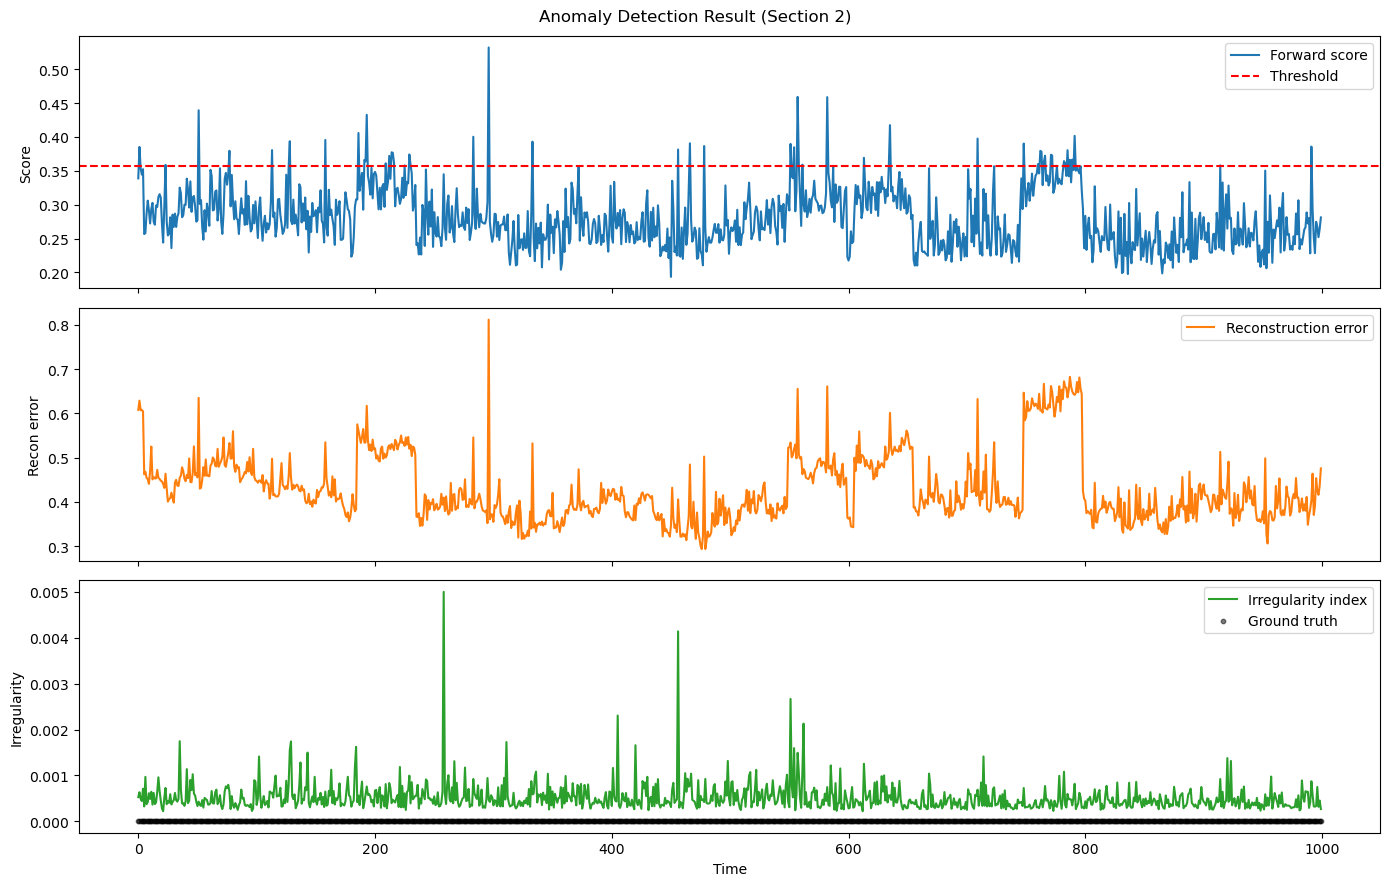


Top-K Anomalies Explanation:
  Index 0: Recon=0.4400, Grad=0.0284, Noise=1.6414


In [50]:
run_visualization(model, data_dict, section_idx=2, length=1000)


Section 0 Analysis

Top 5 Anomaly Locations:
  1. Index 10612: Score=2312.8904, GT=0.0
  2. Index 10619: Score=2310.5769, GT=0.0
  3. Index 10621: Score=2309.6565, GT=0.0
  4. Index 10622: Score=2309.2073, GT=0.0
  5. Index 10607: Score=2307.3247, GT=0.0

--- Anomaly 1 at Index 10612 (Window: 10412-10812) ---


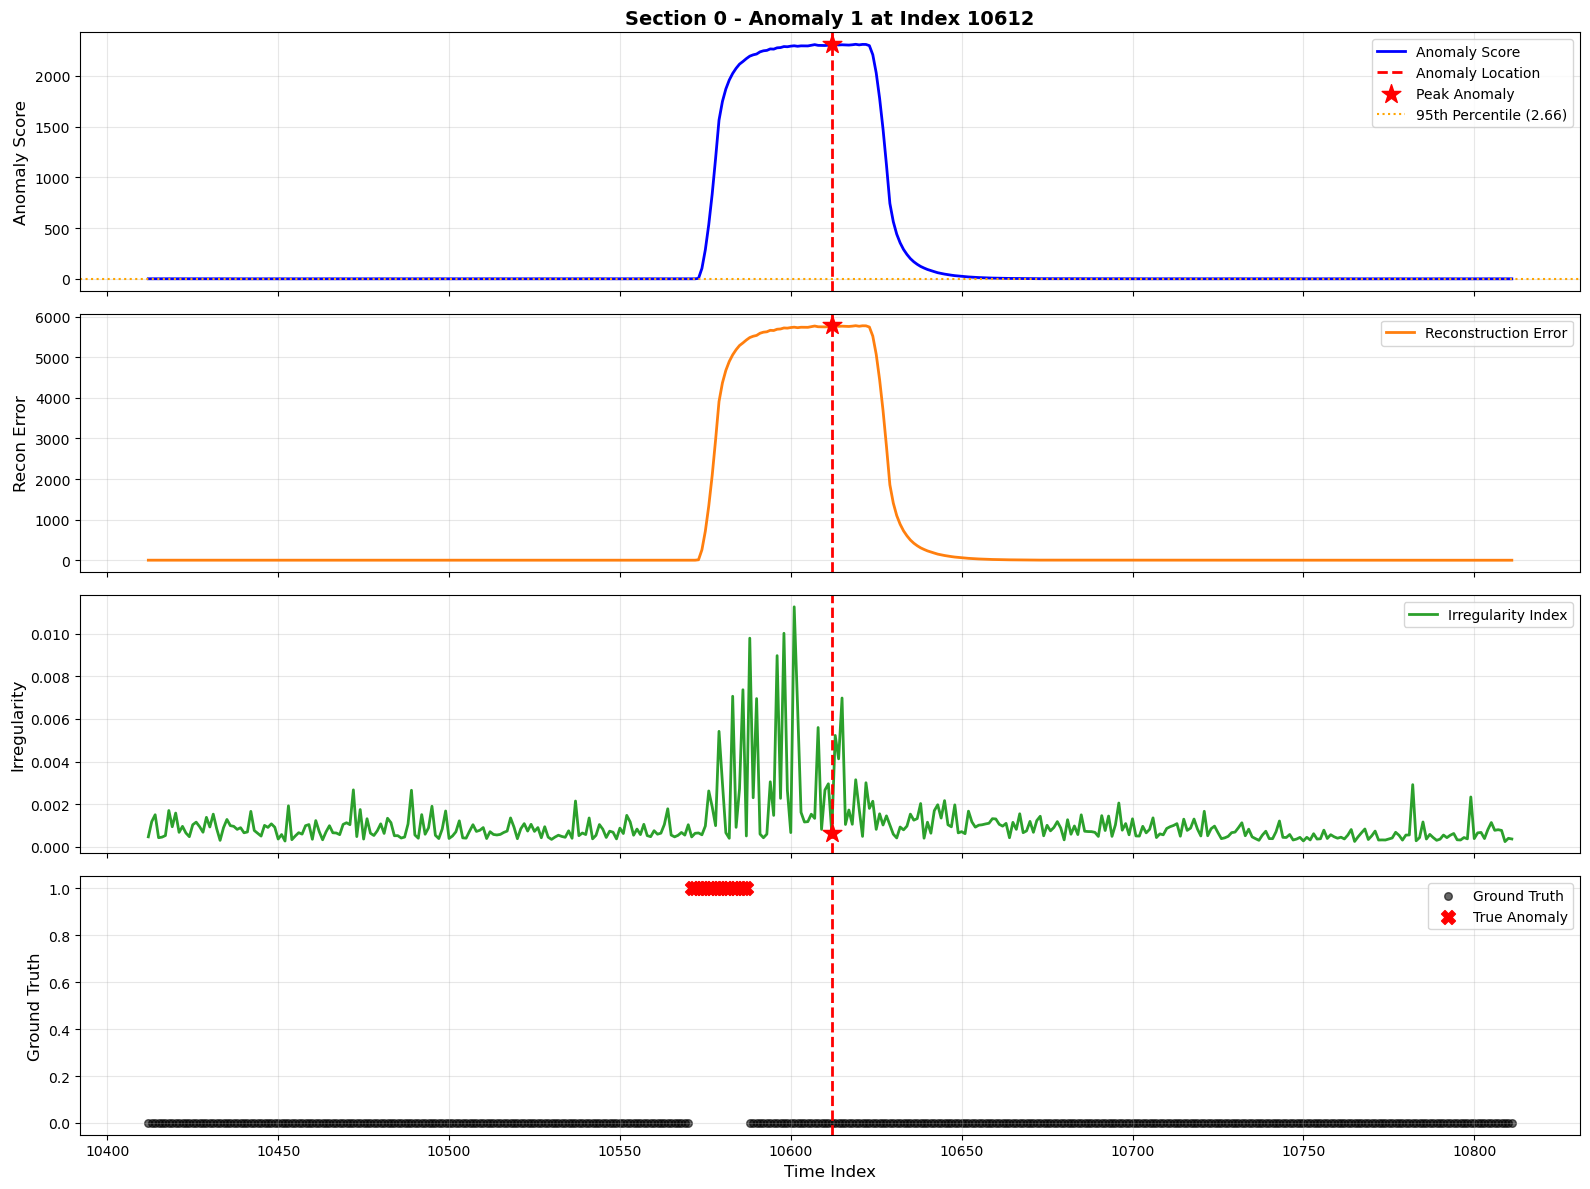

  Anomaly Score: 2312.8904
  Reconstruction Error: 5781.2969
  Irregularity Index: 0.0006
  Ground Truth: 0.0 (Normal)

--- Anomaly 2 at Index 10619 (Window: 10419-10819) ---


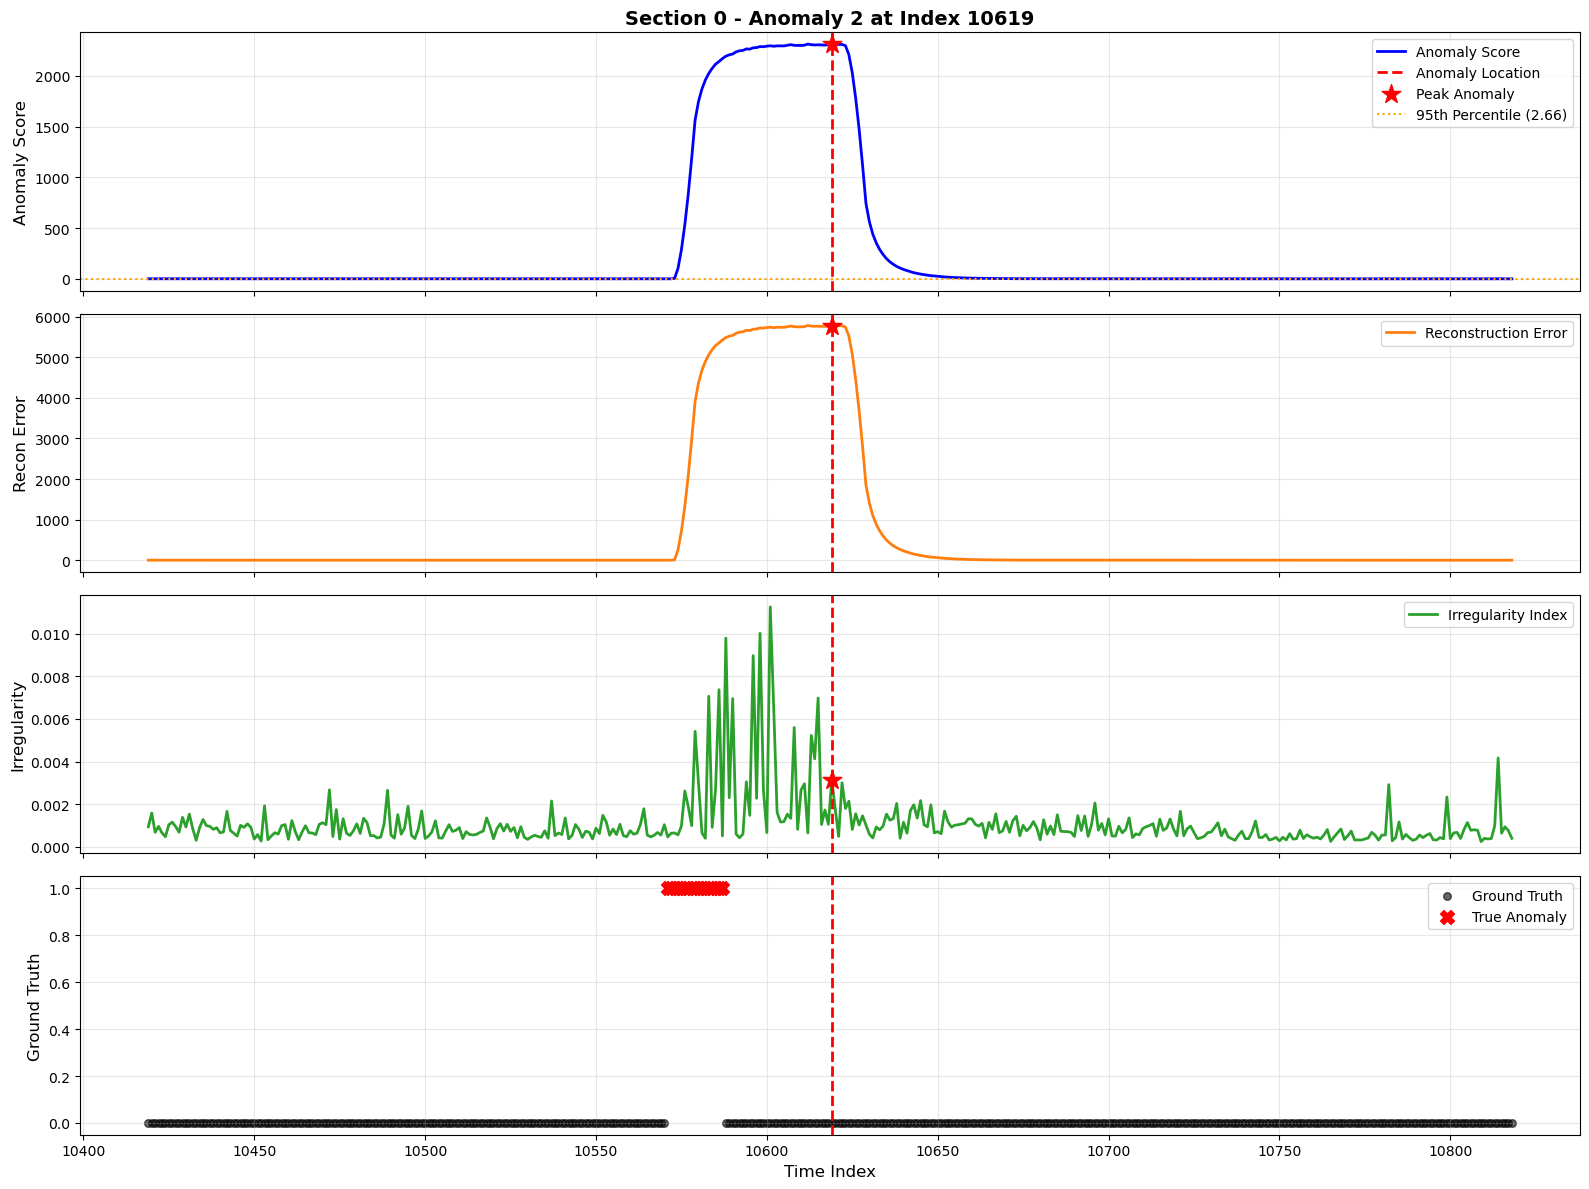

  Anomaly Score: 2310.5769
  Reconstruction Error: 5775.5352
  Irregularity Index: 0.0031
  Ground Truth: 0.0 (Normal)

--- Anomaly 3 at Index 10621 (Window: 10421-10821) ---


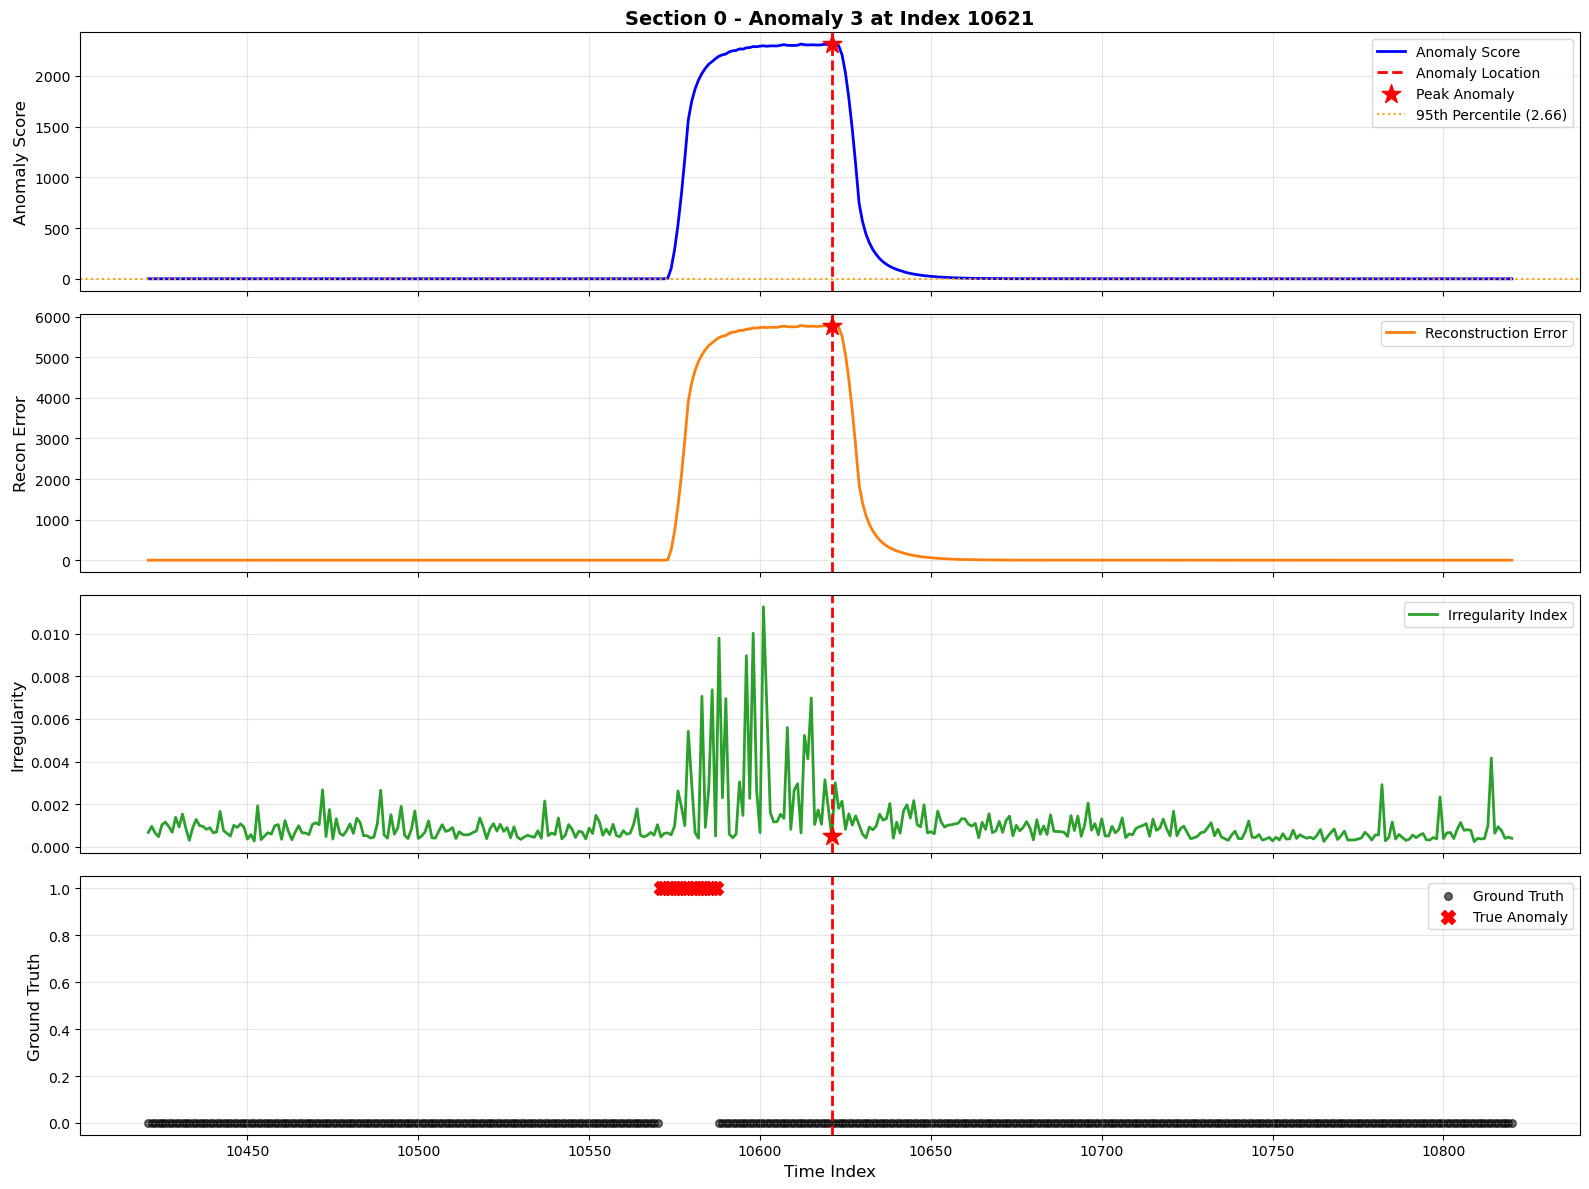

  Anomaly Score: 2309.6565
  Reconstruction Error: 5773.2925
  Irregularity Index: 0.0005
  Ground Truth: 0.0 (Normal)

--- Anomaly 4 at Index 10622 (Window: 10422-10822) ---


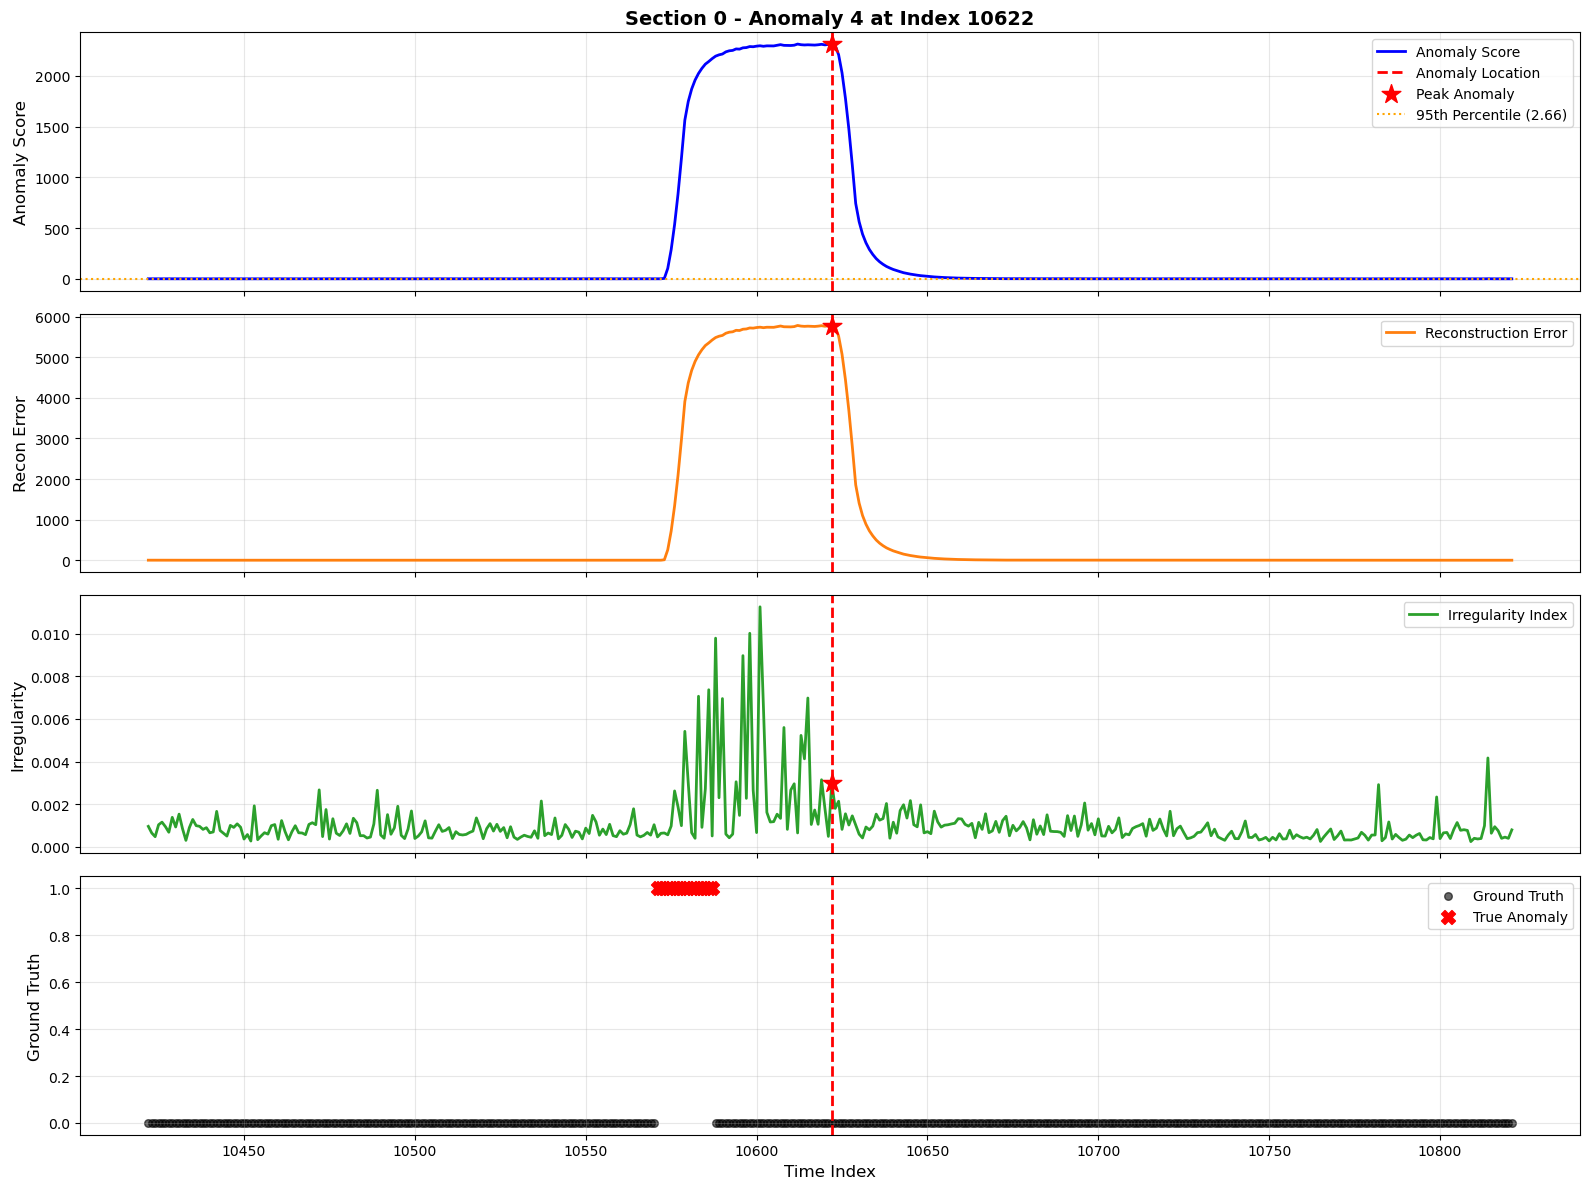

  Anomaly Score: 2309.2073
  Reconstruction Error: 5772.0767
  Irregularity Index: 0.0030
  Ground Truth: 0.0 (Normal)

--- Anomaly 5 at Index 10607 (Window: 10407-10807) ---


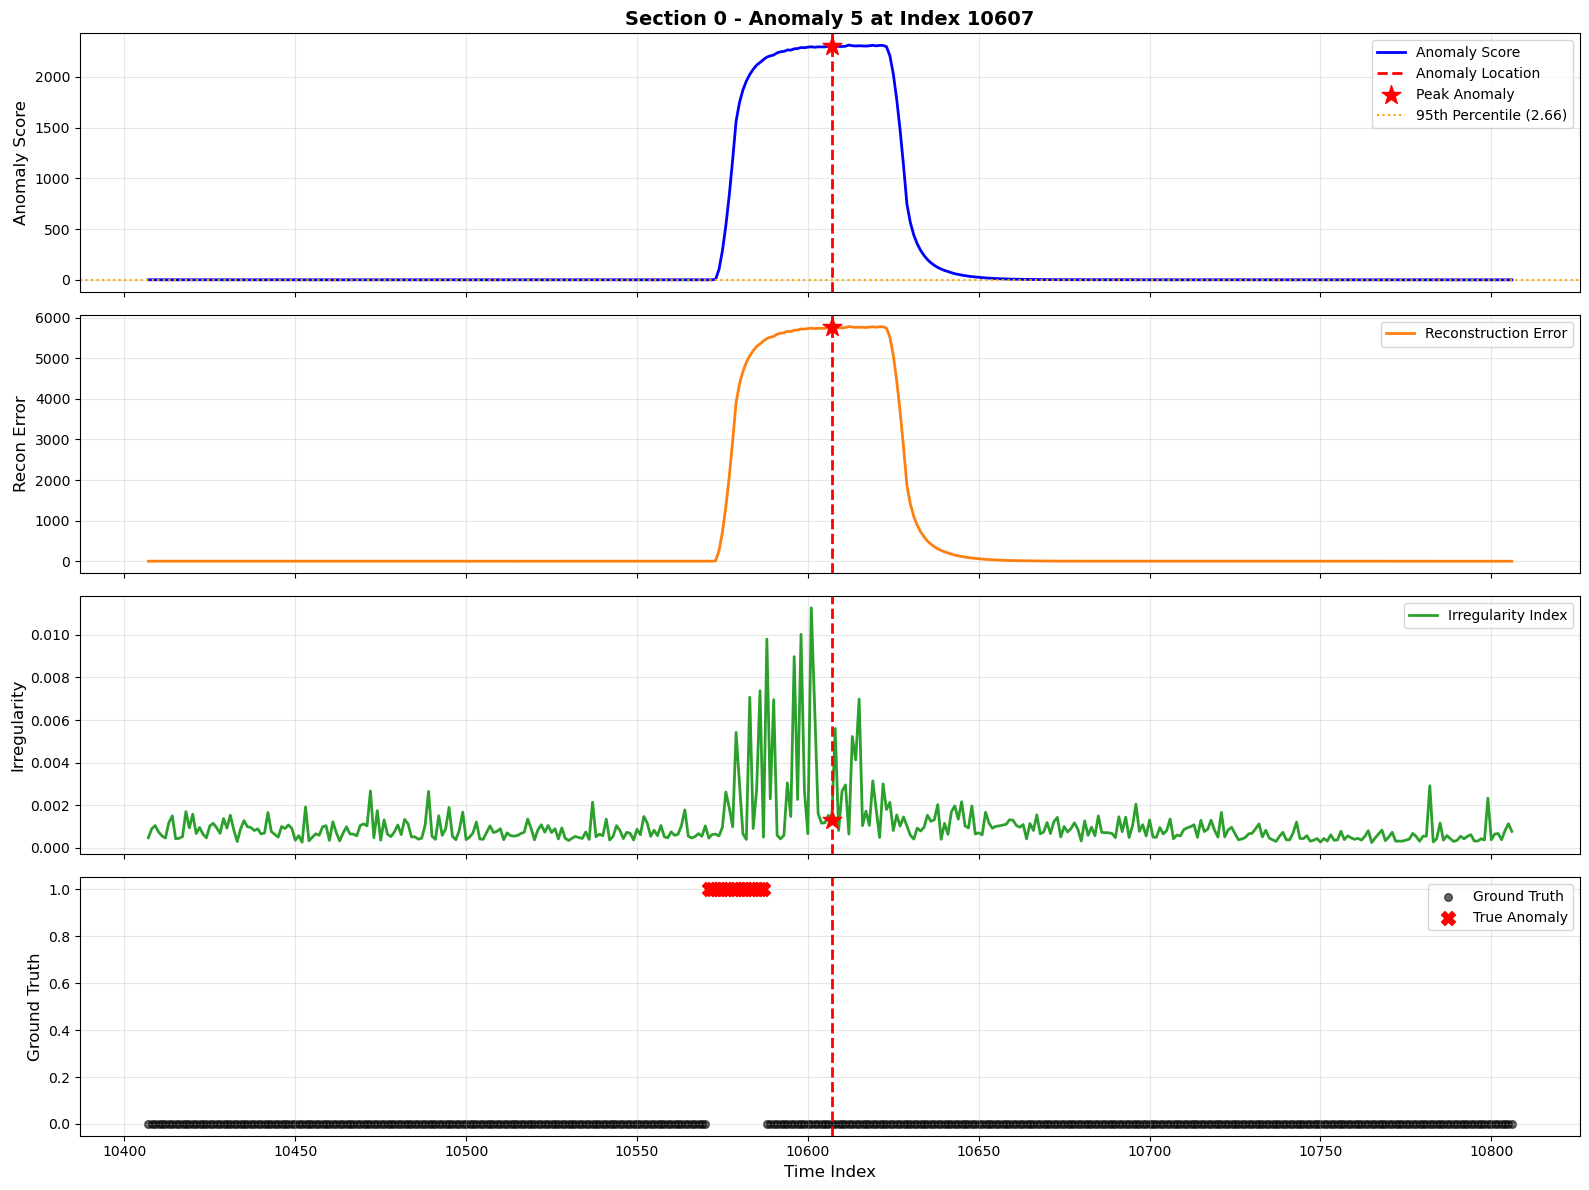

  Anomaly Score: 2307.3247
  Reconstruction Error: 5767.3418
  Irregularity Index: 0.0013
  Ground Truth: 0.0 (Normal)




In [58]:
visualize_all_sections_with_anomalies(
    model, 
    data_dict, 
    window_radius=200,  # 이상 위치 전후 200 시점
    top_k=5  # 상위 5개 이상 위치 시각화
)